# Task-Aware Amortized Importance Sampling — VAE Follow-Up and Failure Analysis

**A reproducible follow-up to your original 25-seed Colab notebook.** This version **reuses the original VAE, probability model, splits, allocation algorithm, and numerical definitions**, while adding experiments that distinguish proposal mismatch, posterior-reference uncertainty, and poor difficulty prediction. The original confirmation notebook remains unchanged.

### Prespecified question

Does a task-aware allocation improve posterior-mean estimation *after controlling proposal quality*, and, if not, is the limitation due to a noisy importance proposal or an inaccurate offline difficulty predictor?

**Important:** An apparent improvement is not guaranteed. The experiment is useful even if it finds no effect. This is a *follow-up* designed after looking at the original 25-seed results; describe all new hypothesis tests as **exploratory** unless independently preregistered and repeated on new data/models.

- 25 separately initialized VAE fits each at latent dimensions 4 and 8; same 8×8 digit dataset and Gaussian decoder as the original.
- Use the **104 test images that the original confirmation notebook did not evaluate**. Both methods receive the *same* test images and the same sample budget.
- Select an importance proposal on validation images only, comparing encoder proposals with tempered and defensive-mixture alternatives; **do not choose by test MSE**.
- Independently estimate the reference posterior twice at increasing numbers of importance samples. Report reference ESS, disagreement, and error stability; no exact posterior means are claimed.
- Independently check ranking of 512-sample learned difficulty scores against a higher-budget validation proxy.
- Compare encoder and selected proposals, then uniform, ESS-derived, task-aware and shuffled allocation *within* each proposal.
- Save models, per-seed CSVs, references, diagnostics, figures, configuration and generated research statement. **All reported numbers come from the run.**

### How to run

1. Open this `.ipynb` in Colab, choose **Runtime → Change runtime type → GPU**.
2. In the first Python configuration cell, change `USE_GOOGLE_DRIVE = True` if you want to resume across sessions. The Drive mount is interactive.
3. At the follow-up configuration cell, leave `FOLLOWUP_MODE = "full"` to run the final study, or use `"smoke"` *only* for a short correctness test.
4. **Runtime → Run all.** The notebook skips the original confirmation's full experimental loop; this notebook runs the new follow-up instead.
5. Review diagnostics before using any result in your SOP. A bad reference diagnostic means the computed MSE is not a reliable posterior-truth comparison.

**Ethics of comparison:** offline proposal selection, teacher training, and reference evaluations are *not free*. The notebook logs their density-evaluation costs separately from the matched online budgets. Results are conditional on this VAE architecture and fixed held-out image set.

## 1 · Runtime, persistence, and settings

In Colab select **Runtime → Change runtime type → GPU**. Run cells **in order**. For long runs, set `USE_GOOGLE_DRIVE=True` to save seed-by-seed results in Drive; rerunning the same configuration skips completed seeds. `RUN_MODE="smoke"` tests the full pipeline quickly **but its output is not valid for SOP claims**. Leave `RUN_MODE="full"` for research results.

In [1]:
import os, sys, json, math, random, time, hashlib, platform
from pathlib import Path
from dataclasses import dataclass, asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
import torch
from torch import nn
from torch.nn import functional as F
from tqdm.auto import tqdm
from IPython.display import display

# RESEARCH settings: do not change after inspecting final results.
RUN_MODE = "full"           # "full" or "smoke" (for debugging only)
USE_GOOGLE_DRIVE = True    # set True for persistent Colab checkpoints
RUN_8D_SECONDARY = False    # True runs 8D as an additional, exploratory architecture

@dataclass(frozen=True)
class Config:
    latent_dims: tuple = (4,)
    n_seeds: int = 25
    epochs: int = 65
    batch_size: int = 128
    hidden: int = 128
    decoder_sigma: float = 0.15
    learning_rate: float = 1e-3
    k_teacher: int = 512
    n_dev: int = 800
    n_predictor_validation: int = 128
    n_test: int = 256
    group_size: int = 64
    k_average: int = 48
    k_min: int = 4
    k_max: int = 120
    online_repeats: int = 12
    n_reference_each: int = 16_384
    reference_chunk: int = 2_048
    reference_image_batch: int = 16
    seed_start: int = 27_000
    split_seed: int = 2_026
    bootstrap_repeats: int = 10_000
    signflip_repeats: int = 100_000

if RUN_MODE == "full":
    cfg = Config(latent_dims=(4, 8) if RUN_8D_SECONDARY else (4,))
elif RUN_MODE == "smoke":
    cfg = Config(n_seeds=2, epochs=2, n_dev=96,
                 n_predictor_validation=32, n_test=64,
                 online_repeats=2, n_reference_each=256,
                 reference_chunk=128, reference_image_batch=16,
                 bootstrap_repeats=200, signflip_repeats=200)
else:
    raise ValueError('RUN_MODE must be "full" or "smoke"')

assert cfg.n_test % cfg.group_size == 0
assert cfg.k_min <= cfg.k_average <= cfg.k_max
assert cfg.n_dev <= 1000 and cfg.n_reference_each % cfg.reference_chunk == 0

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        root = Path('/content/drive/MyDrive/TaskAware_VAE_Confirmation')
    except ImportError:
        raise RuntimeError('Google Drive mounting is available in Google Colab only.')
else:
    root = Path('/content/TaskAware_VAE_Confirmation') if 'google.colab' in sys.modules else Path('TaskAware_VAE_Confirmation')

run_hash = hashlib.sha256(json.dumps(asdict(cfg), sort_keys=True).encode()).hexdigest()[:12]
OUT = root / f'{RUN_MODE}_{run_hash}'
OUT.mkdir(parents=True, exist_ok=True)
(OUT/'config.json').write_text(json.dumps({'mode':RUN_MODE, **asdict(cfg)}, indent=2))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
print('Torch:', torch.__version__, 'Sklearn:', sklearn.__version__)
print('Results:', OUT.resolve())
print('Configuration:', asdict(cfg))
if DEVICE.type != 'cuda':
    print('WARNING: no CUDA GPU detected. The full experiment may be slow.')
if RUN_MODE == 'smoke':
    print('SMOKE TEST ONLY — not enough data for an SOP claim.')

Mounted at /content/drive
Device: cuda
Torch: 2.14.1+cu130 Sklearn: 1.6.1
Results: /content/drive/MyDrive/TaskAware_VAE_Confirmation/full_0a59e4b74a5d
Configuration: {'latent_dims': (4,), 'n_seeds': 25, 'epochs': 65, 'batch_size': 128, 'hidden': 128, 'decoder_sigma': 0.15, 'learning_rate': 0.001, 'k_teacher': 512, 'n_dev': 800, 'n_predictor_validation': 128, 'n_test': 256, 'group_size': 64, 'k_average': 48, 'k_min': 4, 'k_max': 120, 'online_repeats': 12, 'n_reference_each': 16384, 'reference_chunk': 2048, 'reference_image_batch': 16, 'seed_start': 27000, 'split_seed': 2026, 'bootstrap_repeats': 10000, 'signflip_repeats': 100000}


## 2 · Frozen, disjoint data partitions

Train and fit the VAE on the training split. Train the offline allocation predictors on **800 training images**. Use validation images only for a predictor diagnostic, never for final allocation fitting or model selection. All four allocation methods use the same unseen 256-image test set and the same seeds. The digit split is fixed across the 25 VAE training seeds; this distinguishes *variation across training runs* from *variation across datasets*.

In [2]:
def fix_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def torch_rng(seed):
    g = torch.Generator(device=DEVICE.type)
    g.manual_seed(int(seed))
    return g

all_x, all_y = load_digits(return_X_y=True)
all_x = (all_x.astype(np.float32) / 16.0)
all_y = all_y.astype(int)
indices = np.arange(len(all_x))
train_val_idx, test_idx = train_test_split(
    indices, test_size=0.20, random_state=cfg.split_seed, stratify=all_y)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.20, random_state=cfg.split_seed+1,
    stratify=all_y[train_val_idx])
select_test, _ = train_test_split(
    test_idx, train_size=cfg.n_test,
    random_state=cfg.split_seed+2, stratify=all_y[test_idx])
rng_partition = np.random.default_rng(cfg.split_seed+3)
select_dev = rng_partition.choice(train_idx, cfg.n_dev, replace=False)
select_val = rng_partition.choice(val_idx, cfg.n_predictor_validation, replace=False)

x_train = torch.as_tensor(all_x[train_idx], dtype=torch.float32)
x_dev = torch.as_tensor(all_x[select_dev], dtype=torch.float32)
x_valid = torch.as_tensor(all_x[select_val], dtype=torch.float32)
x_test = torch.as_tensor(all_x[select_test], dtype=torch.float32)
assert set(train_idx).isdisjoint(test_idx) and set(train_idx).isdisjoint(val_idx)
assert set(val_idx).isdisjoint(test_idx)
assert len(x_test)==cfg.n_test and len(x_dev)==cfg.n_dev
print('Train:', len(train_idx), 'Validation:',len(val_idx), 'Test:',len(test_idx))
print('Predictor development:',len(x_dev),'Validation diagnostic:',len(x_valid), 'Final test:',len(x_test))
print('Test digit distribution:',np.bincount(all_y[select_test],minlength=10))

Train: 1149 Validation: 288 Test: 360
Predictor development: 800 Validation diagnostic: 128 Final test: 256
Test digit distribution: [26 26 25 26 26 26 25 26 25 25]


## 3 · Explicit probabilistic model and training

The VAE uses a standard normal prior `p(z)=N(0,I)`, diagonal-Gaussian encoder `qφ(z|x)`, and **fixed-variance Gaussian decoder** `pθ(x|z)=N(decoderθ(z), 0.15²I)`. This is suitable for continuously valued grayscale pixels. The negative-ELBO training loss has reconstruction term `||x - decoder(z)||² / (2 σ²)` plus analytic Gaussian KL, with constants independent of model parameters omitted.

All methods compare inference under the *same* trained VAE and encoder proposal. The 25 VAE runs are independent initializations/training randomness on the same frozen split. The result concerns this specific architecture and decoder likelihood.

In [3]:
LOG2PI = float(np.log(2.0 * np.pi))
class GaussianVAE(nn.Module):
    def __init__(self, latent_dim, hidden=128, decoder_sigma=0.15):
        super().__init__()
        self.latent_dim = latent_dim
        self.decoder_sigma = float(decoder_sigma)
        self.encoder = nn.Sequential(nn.Linear(64,hidden), nn.ReLU(),
                                     nn.Linear(hidden,hidden), nn.ReLU())
        self.fc_mu = nn.Linear(hidden,latent_dim)
        self.fc_lv = nn.Linear(hidden,latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim,hidden),nn.ReLU(),
                                     nn.Linear(hidden,hidden),nn.ReLU(),
                                     nn.Linear(hidden,64),nn.Sigmoid())

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_lv(h).clamp(-10., 6.)

    def forward(self, x):
        mu, lv = self.encode(x)
        z = mu + torch.exp(0.5*lv) * torch.randn_like(mu)
        return self.decoder(z), mu, lv

def train_vae(model, xtrain, seed):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=cfg.learning_rate)
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(xtrain),
        batch_size=cfg.batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed))
    hist=[]
    for epoch in range(cfg.epochs):
        total=0.0
        for (xb_cpu,) in loader:
            xb=xb_cpu.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            recon,mu,lv = model(xb)
            rec=((xb-recon)**2).sum(1)/(2*model.decoder_sigma**2)
            kl=-0.5*torch.sum(1+lv-mu.square()-lv.exp(),dim=1)
            loss=(rec+kl).mean()
            if not torch.isfinite(loss):
                raise FloatingPointError('VAE loss became non-finite')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),5.0)
            opt.step()
            total+=float(loss.detach())*len(xb)
        hist.append({'seed':seed,'epoch':epoch+1,'negative_elbo_without_const':total/len(xtrain)})
    model.eval()
    return pd.DataFrame(hist)

@torch.inference_mode()
def get_features(model, xs, batch=128):
    blocks=[]
    for begin in range(0,len(xs),batch):
        x=xs[begin:begin+batch].to(DEVICE)
        mu,lv=model.encode(x)
        qstd=torch.exp(0.5*lv)
        rec=model.decoder(mu)
        kl=-0.5*(1+lv-mu.square()-lv.exp()).sum(dim=1,keepdim=True)
        features=torch.cat([
            x,x.square(),torch.linalg.vector_norm(x,dim=1,keepdim=True),
            torch.linalg.vector_norm(mu,dim=1,keepdim=True),
            qstd.mean(dim=1,keepdim=True),qstd.max(dim=1,keepdim=True).values,
            ((x-rec)**2).mean(dim=1,keepdim=True),kl,
            torch.full((len(x),1),model.decoder_sigma,device=DEVICE)
        ],dim=1)
        blocks.append(features.cpu().numpy())
    return np.concatenate(blocks).astype(np.float32)

@torch.inference_mode()
def draw_logweights(model, xb, count, generator):
    """Return z[n,K,d], log p(z)+log p(x|z)-log q(z|x)[n,K]."""
    xb=xb.to(DEVICE)
    mu,lv=model.encode(xb)
    std=torch.exp(0.5*lv)
    z=mu[:,None,:] + std[:,None,:]*torch.randn(
        (len(xb),int(count),model.latent_dim),device=DEVICE,generator=generator)
    recon=model.decoder(z.reshape(-1,model.latent_dim)).reshape(len(xb),count,64)
    log_pz=-0.5*(z.square()+LOG2PI).sum(dim=-1)
    log_q=-0.5*(((z-mu[:,None,:])/std[:,None,:]).square()
                  +lv[:,None,:]+LOG2PI).sum(dim=-1)
    log_px=-0.5*((xb[:,None,:]-recon).square()/model.decoder_sigma**2
                 +2*math.log(model.decoder_sigma)+LOG2PI).sum(dim=-1)
    lw=log_px+log_pz-log_q
    if not torch.isfinite(lw).all():
        raise FloatingPointError('Non-finite importance weight')
    return z,lw

## 4 · Train **matched** offline allocation predictors

For each development observation, use the same teacher draws to construct both targets:

\[\widehat{\tau^2}_i=K_{dev}\sum_k \widetilde{w}_{ik}^2\|z_{ik}-\widehat\mu_i\|^2,\qquad
\widehat{\operatorname{ESS}}_i=\left(\sum_k\widetilde{w}_{ik}^2\right)^{-1}.\]

The task score is `sqrt(max(tau², 1e-5)) + 0.02`; ESS score is `sqrt(max(Kdev/ESS - 1,0)) + 0.05`, following the report's stabilized teacher score idea. Train two identical `HistGradientBoostingRegressor` architectures on the **log scores**. Predicted scores use no online pilot calls. The held-out predictor-validation diagnostic is reported, **not used to adjust final methods**.

In [4]:
@torch.inference_mode()
def teacher_scores(model, xs, seed):
    g=torch_rng(seed)
    task_scores=[]; ess_scores=[]
    for begin in range(0,len(xs),32):
        z,lw=draw_logweights(model,xs[begin:begin+32],cfg.k_teacher,g)
        weights=torch.softmax(lw,dim=1)
        m=(weights[:,:,None]*z).sum(dim=1)
        tau2=cfg.k_teacher*(weights.square()*(z-m[:,None,:]).square().sum(dim=-1)).sum(dim=1)
        ess=1.0/weights.square().sum(dim=1)
        task=torch.sqrt(tau2.clamp_min(1e-5))+0.02
        essscore=torch.sqrt((cfg.k_teacher/ess-1.).clamp_min(0.))+0.05
        task_scores.extend(task.cpu().numpy().tolist())
        ess_scores.extend(essscore.cpu().numpy().tolist())
    return np.asarray(task_scores),np.asarray(ess_scores)

def fit_predictors(model, dim, seed):
    feat=get_features(model,x_dev)
    score_task,score_ess=teacher_scores(model,x_dev,seed+1_100_000)
    params=dict(max_iter=130,max_leaf_nodes=10,l2_regularization=2.0,
                min_samples_leaf=20,random_state=seed)
    task_reg=HistGradientBoostingRegressor(**params).fit(feat,np.log(score_task))
    ess_reg=HistGradientBoostingRegressor(**params).fit(feat,np.log(score_ess))
    val_feat=get_features(model,x_valid)
    val_task,val_ess=teacher_scores(model,x_valid,seed+1_200_000)
    pred_task_val=np.exp(task_reg.predict(val_feat))
    pred_ess_val=np.exp(ess_reg.predict(val_feat))
    rho_task=stats.spearmanr(pred_task_val,val_task).statistic
    rho_ess=stats.spearmanr(pred_ess_val,val_ess).statistic
    feat_test=get_features(model,x_test)
    pred_task=np.exp(task_reg.predict(feat_test)).clip(1e-6,1e6)
    pred_ess=np.exp(ess_reg.predict(feat_test)).clip(1e-6,1e6)
    return pred_task,pred_ess,{
        'latent_dim':dim,'seed':seed,
        'task_teacher_vs_pred_spearman_val':float(rho_task),
        'ess_teacher_vs_pred_spearman_val':float(rho_ess),
        'teacher_budget':cfg.k_teacher,'n_dev':cfg.n_dev,
        'val_task_score_std':float(np.std(val_task))}

## 5 · Reference posterior expectations, independent replications, and ESS

This is the largest GPU step. Streaming log-weight sums keep memory bounded. Two disjoint random-number streams give `ref_A` and `ref_B`. We combine the pools using their summed importance weights, not a simple average of their posterior means. **Neither independent high-budget run is exact ground truth.** Their disagreement and combined ESS/sample ratio are diagnostics of how trustworthy this estimated reference is.

In [5]:
@torch.inference_mode()
def reference_pass(model, xs, seed):
    ref_mu=[];ref_logz=[];ref_ess=[]
    g=torch_rng(seed)
    for begin in range(0,len(xs),cfg.reference_image_batch):
        xb=xs[begin:begin+cfg.reference_image_batch]
        n=len(xb);d=model.latent_dim
        # Accumulate sums after multiplying by exp(-max log-weight).
        maxlog=torch.full((n,),-float('inf'),device=DEVICE,dtype=torch.float64)
        sumw=torch.zeros(n,device=DEVICE,dtype=torch.float64)
        sumwz=torch.zeros((n,d),device=DEVICE,dtype=torch.float64)
        sumw2=torch.zeros(n,device=DEVICE,dtype=torch.float64)
        for _ in range(0,cfg.n_reference_each,cfg.reference_chunk):
            z,lw=draw_logweights(model,xb,cfg.reference_chunk,g)
            lw=lw.double(); z=z.double()
            new_max=torch.maximum(maxlog,lw.max(dim=1).values)
            oldscale=torch.exp(maxlog-new_max)
            neww=torch.exp(lw-new_max[:,None])
            sumw=sumw*oldscale+neww.sum(dim=1)
            sumwz=sumwz*oldscale[:,None]+(neww[:,:,None]*z).sum(dim=1)
            sumw2=sumw2*oldscale.square()+neww.square().sum(dim=1)
            maxlog=new_max
        mu=sumwz/sumw[:,None]
        lz=maxlog+sumw.log()-math.log(cfg.n_reference_each)
        ess=sumw.square()/sumw2
        ref_mu.append(mu.cpu().numpy())
        ref_logz.append(lz.cpu().numpy())
        ref_ess.append(ess.cpu().numpy())
    return (np.concatenate(ref_mu),np.concatenate(ref_logz),np.concatenate(ref_ess))

def make_references(model,dim,seed):
    a,za,essa=reference_pass(model,x_test,seed+2_100_000)
    b,zb,essb=reference_pass(model,x_test,seed+2_200_000)
    lsum=np.logaddexp(za,zb)
    pa=np.exp(za-lsum)
    pb=np.exp(zb-lsum)
    mu=pa[:,None]*a+pb[:,None]*b
    logz=lsum-math.log(2.0)
    ess_comb=1.0/(pa**2/essa + pb**2/essb)
    reference_disagreement=((a-b)**2).mean(axis=1)
    diag={
        'latent_dim':dim,'seed':seed,
        'reference_pair_mse':float(reference_disagreement.mean()),
        'reference_pair_logz_mae':float(np.mean(np.abs(za-zb))),
        'reference_ess_fraction_median':float(np.median(ess_comb/(2*cfg.n_reference_each))),
        'reference_ess_fraction_p05':float(np.percentile(ess_comb/(2*cfg.n_reference_each),5)),
        'reference_ess_fraction_below_1pct':float(np.mean(ess_comb/(2*cfg.n_reference_each)<0.01))}
    return {'mu':mu,'logz':logz,'a':a,'b':b,'za':za,'zb':zb},diag

## 6 · Capped sample allocation with exact group budgets

The unconstrained optimal asymptotic allocation to minimize a sum of per-observation posterior-mean variances is proportional to `sqrt(tau²)`. We impose `4 ≤ Kᵢ ≤ 120`, a total of `64 × 48 = 3072` per group, and integer allocations. `ESSBased` applies the same allocation mechanism to the separate ESS-derived difficulty score. `ShuffledTask` preserves the distribution of task scores while removing their correspondence to images.

In [6]:
def bounded_allocate(scores,budget,kmin,kmax):
    score=np.asarray(scores,dtype=float)
    if len(score)==0 or not np.isfinite(score).all() or (score<=0).any():
        raise ValueError('Allocation scores must be finite, positive and non-empty')
    n=len(score)
    if not(n*kmin <= budget <= n*kmax):
        raise ValueError('Budget infeasible')
    extra=int(budget-n*kmin)
    cap=int(kmax-kmin)
    if extra==0:return np.full(n,kmin,dtype=int)
    if extra==n*cap:return np.full(n,kmax,dtype=int)
    lo=0.0;hi=1.0
    # Find a Lagrange multiplier for capped proportional extras.
    while np.minimum(hi*score,cap).sum()<extra:
        hi*=2.0
    for _ in range(70):
        mid=(lo+hi)*0.5
        if np.minimum(mid*score,cap).sum()<extra:
            lo=mid
        else:
            hi=mid
    fractional=np.minimum(hi*score,cap)
    rounded=np.floor(fractional+1e-10).astype(int)
    remaining=int(extra-rounded.sum())
    if remaining>0:
        eligibility=np.flatnonzero(rounded<cap)
        order=eligibility[np.argsort(-(fractional[eligibility]-rounded[eligibility]),kind='stable')]
        assert remaining<=len(order)
        rounded[order[:remaining]]+=1
    out=rounded+kmin
    assert np.sum(out)==budget and out.min()>=kmin and out.max()<=kmax
    return out

def make_allocations(pred_task,pred_ess,seed):
    result={n:np.zeros(len(x_test),dtype=int) for n in
            ('Uniform','TaskAware','ESSBased','ShuffledTask')}
    budget=cfg.group_size*cfg.k_average
    for gi,start in enumerate(range(0,len(x_test),cfg.group_size)):
        idx=slice(start,start+cfg.group_size)
        p_task=pred_task[idx]
        p_ess=pred_ess[idx]
        shuf=np.random.default_rng(seed+gi+3_000_000).permutation(p_task)
        result['Uniform'][idx]=bounded_allocate(np.ones_like(p_task),budget,cfg.k_min,cfg.k_max)
        result['TaskAware'][idx]=bounded_allocate(p_task,budget,cfg.k_min,cfg.k_max)
        result['ESSBased'][idx]=bounded_allocate(p_ess,budget,cfg.k_min,cfg.k_max)
        result['ShuffledTask'][idx]=bounded_allocate(shuf,budget,cfg.k_min,cfg.k_max)
    for name,ki in result.items():
        assert np.all(ki>=cfg.k_min) and np.all(ki<=cfg.k_max)
        assert np.mean(ki)==cfg.k_average
        for j in range(0,len(ki),cfg.group_size):
            assert ki[j:j+cfg.group_size].sum()==budget
    return result

## 7 · Paired evaluation and diagnostics

Each seed gets its **own** trained VAE and its **own** offline predictors. For every online repeat, all methods reuse a single bank of 120 proposal draws per image and take the first `Kᵢ` draws indicated by their allocation. This uses common random numbers across methods, making paired comparisons less noisy. It does **not** give any method more than its allocated online queries.

In [7]:
@torch.inference_mode()
def evaluate_online(model,refs,allocations,dim,seed):
    records=[]
    counts={name:torch.as_tensor(values,device=DEVICE,dtype=torch.long)
            for name,values in allocations.items()}
    muc=torch.as_tensor(refs['mu'],device=DEVICE,dtype=torch.float64)
    mua=torch.as_tensor(refs['a'],device=DEVICE,dtype=torch.float64)
    mub=torch.as_tensor(refs['b'],device=DEVICE,dtype=torch.float64)
    lzc=torch.as_tensor(refs['logz'],device=DEVICE,dtype=torch.float64)
    lza=torch.as_tensor(refs['za'],device=DEVICE,dtype=torch.float64)
    lzb=torch.as_tensor(refs['zb'],device=DEVICE,dtype=torch.float64)
    arange_k=torch.arange(cfg.k_max,device=DEVICE)
    for rep in range(cfg.online_repeats):
        g=torch_rng(seed+4_000_000+rep)
        # test set fits in GPU: 256 x 120 x 4 (plus decoder activations)
        z,lw=draw_logweights(model,x_test,cfg.k_max,g)
        z=z.double();lw=lw.double()
        for name,ki in counts.items():
            mask=arange_k[None,:]<ki[:,None]
            masked_lw=lw.masked_fill(~mask,-float('inf'))
            weight=torch.softmax(masked_lw,dim=1)
            mu_hat=(weight[:,:,None]*z).sum(dim=1)
            logz_hat=torch.logsumexp(masked_lw,dim=1)-ki.double().log()
            rec={
                'latent_dim':dim,'seed':seed,'rep':rep,'method':name,
                'mse':float((mu_hat-muc).square().mean()),
                'mse_ref_A':float((mu_hat-mua).square().mean()),
                'mse_ref_B':float((mu_hat-mub).square().mean()),
                'logz_abs_error_ref':float((logz_hat-lzc).abs().mean()),
                'logz_abs_error_ref_A':float((logz_hat-lza).abs().mean()),
                'logz_abs_error_ref_B':float((logz_hat-lzb).abs().mean()),
                'mean_samples':float(ki.float().mean())}
            records.append(rec)
    allocation_rows=[]
    for name,arr in allocations.items():
        allocation_rows.append({'latent_dim':dim,'seed':seed,'method':name,
            'min_samples':int(arr.min()),'max_samples':int(arr.max()),
            'mean_samples':float(arr.mean()),'std_samples':float(arr.std()),
            'fraction_at_min':float((arr==cfg.k_min).mean()),
            'fraction_at_max':float((arr==cfg.k_max).mean())})
    return pd.DataFrame(records),pd.DataFrame(allocation_rows)

## 8 · Follow-up configuration and fresh held-out images

The original split selected 256 out of 360 test images. This experiment uses only the other **104** images. The original `x_test` from the first study is not used for allocation comparisons here. Full mode uses the original 512-sample teacher budget and 48 draws per image. Validation and proposal tuning use separate images from final evaluation.

In [8]:
from dataclasses import dataclass, asdict
import joblib

FOLLOWUP_MODE = "full"  # "full" or "smoke"; smoke numbers MUST NOT be used in SOP
FOLLOWUP_DIMS = (4, 8)  # both dimensions required for the full comparison

@dataclass(frozen=True)
class FollowupConfig:
    dims: tuple = (4,8)
    n_seeds: int = 25
    epochs: int = 65
    n_dev: int = 800
    n_val: int = 128
    n_val_proposal: int = 64
    group_size: int = 52
    online_average: int = 48
    online_repeats: int = 12
    teacher_budget: int = 512
    repeat_teacher: int = 4
    validation_proxy_budget: int = 4096
    proposal_pilot_draws: int = 2048  # per independent reference draw on validation images
    ref_each: int = 32_768             # two independent final passes
    ref_early: int = 8192
    reference_chunk: int = 1024
    ref_image_batch: int = 8
    encoder_ref_subset: int = 32
    seed_start: int = 27_000
    bootstrap_repeats: int = 6000
    signflip_repeats: int = 30_000

if FOLLOWUP_MODE == 'full':
    FC = FollowupConfig(dims=FOLLOWUP_DIMS)
elif FOLLOWUP_MODE == 'smoke':
    FC = FollowupConfig(dims=(4,),n_seeds=1,epochs=2,n_dev=64,n_val=24,
          n_val_proposal=16,group_size=16,online_repeats=2,teacher_budget=64,
          repeat_teacher=2,validation_proxy_budget=128,
          proposal_pilot_draws=128,ref_each=256,ref_early=128,
          reference_chunk=128,ref_image_batch=4,encoder_ref_subset=8,
          bootstrap_repeats=100,signflip_repeats=100)
else:
    raise ValueError('FOLLOWUP_MODE must be full or smoke')

# Split decision was made before this follow-up: unused test images from original split.
seen_test_ids = set(np.asarray(select_test).tolist())
fresh_ids = np.array(sorted(set(np.asarray(test_idx).tolist()) - seen_test_ids))
assert not set(fresh_ids).intersection(seen_test_ids)
assert len(fresh_ids) == len(test_idx)-len(select_test) == 104
if FOLLOWUP_MODE=='smoke':fresh_ids=fresh_ids[:32]
x_follow = torch.as_tensor(all_x[fresh_ids],dtype=torch.float32)
assert len(x_follow) % FC.group_size == 0
assert FC.ref_each % FC.reference_chunk == 0
assert FC.ref_early % FC.reference_chunk == 0
assert FC.n_val_proposal <= FC.n_val <= len(x_valid)
assert FC.n_dev <= len(x_dev)

FU_PARAMS={'followup':asdict(FC),'baseline_cfg':asdict(cfg),
           'fresh_test_ids':fresh_ids.tolist(),
           'proposals':[{'t':0.65,'lam':0.0}, {'t':0.85,'lam':0.0},
                        {'t':1.0,'lam':0.0}, {'t':1.5,'lam':0.0},
                        {'t':2.0,'lam':0.0}, {'t':1.0,'lam':0.10},
                        {'t':1.5,'lam':0.10}, {'t':2.0,'lam':0.20}]}
fu_hash=hashlib.sha256(json.dumps(FU_PARAMS,sort_keys=True).encode()).hexdigest()[:12]
FUOUT=root/f'followup_{FOLLOWUP_MODE}_{fu_hash}'
FUOUT.mkdir(parents=True,exist_ok=True)
(FUOUT/'frozen_configuration.json').write_text(json.dumps(FU_PARAMS,indent=2))
print('Follow-up images:',len(x_follow),'; original tested images:',len(x_test))
print('Follow-up dimensions:',FC.dims,'VAE seeds:',FC.n_seeds,'output:',FUOUT)
if FOLLOWUP_MODE=='smoke':print('WARNING: smoke test is a code check, NOT scientific evidence')

Follow-up images: 104 ; original tested images: 256
Follow-up dimensions: (4, 8) VAE seeds: 25 output: /content/drive/MyDrive/TaskAware_VAE_Confirmation/followup_full_3dde513c60c2


## 9 · Properly weighted Gaussian and defensive-mixture proposals

For a trained VAE, the posterior target remains \(p(z\mid x)\propto p(z)p_\theta(x\mid z)\). We compare proposals, **without modifying the target density**:

\[
q_{T,\lambda}(z\mid x)=(1-\lambda)\,\mathcal N(\mu_\phi(x),T^2\operatorname{diag}\sigma_\phi^2(x))+\lambda\,\mathcal N(0,I).
\]

We sample from the *mixture* and compute log importance weights using the exact **mixture density**, not the density of the sampled component. The 512-budget teacher and online evaluations use the same chosen proposal. This is essential: otherwise the estimate would target the wrong posterior. We include both narrowed and widened Gaussian candidates because proposal mismatch is not necessarily underdispersion.

In [9]:
@dataclass(frozen=True)
class Proposal:
    t: float
    lam: float
    @property
    def name(self):return f't{self.t:.2f}_prior{self.lam:.2f}'

PROPOSALS=[Proposal(**p) for p in FU_PARAMS['proposals']]
ENCODER=Proposal(t=1.0,lam=0.0)
assert ENCODER in PROPOSALS

@torch.inference_mode()
def draw_proposal(model, xb, count, g, proposal):
    xb=xb.to(DEVICE)
    n,d=len(xb),model.latent_dim
    mu,lv=model.encode(xb)
    q_std=torch.exp(.5*lv)*proposal.t
    eps=torch.randn((n,int(count),d),device=DEVICE,generator=g)
    z_enc=mu[:,None,:]+q_std[:,None,:]*eps
    if proposal.lam>0:
        z_prior=torch.randn((n,int(count),d),device=DEVICE,generator=g)
        mask=torch.rand((n,int(count),1),device=DEVICE,generator=g)<proposal.lam
        z=torch.where(mask,z_prior,z_enc)
    else:
        z=z_enc
    lv_t=lv+2*math.log(proposal.t)
    log_enc=-.5*(((z-mu[:,None,:])/q_std[:,None,:]).square()
                  +lv_t[:,None,:]+LOG2PI).sum(-1)
    log_pz=-.5*(z.square()+LOG2PI).sum(-1)
    if proposal.lam>0:
        log_q=torch.logaddexp(log_enc+math.log1p(-proposal.lam),
                              log_pz+math.log(proposal.lam))
    else:
        log_q=log_enc
    rec=model.decoder(z.reshape(-1,d)).reshape(n,int(count),64)
    log_px=-.5*((xb[:,None,:]-rec).square()/model.decoder_sigma**2
                   +2*math.log(model.decoder_sigma)+LOG2PI).sum(-1)
    lw=log_pz+log_px-log_q
    if not torch.isfinite(lw).all():raise FloatingPointError('Nonfinite logweights')
    return z,lw

# Sanity check 1: pure encoder proposal matches the original implementation
# at the level of the analytic log-density calculation; no target change.
with torch.inference_mode():
    toy_mu=torch.tensor([[0.2,-0.1]],device=DEVICE)
    toy_std=torch.tensor([[1.1,0.7]],device=DEVICE)
    toy_z=torch.tensor([[[0.,.4],[1.,-.2]]],device=DEVICE)
    log0=-.5*((((toy_z-toy_mu[:,None,:])/toy_std[:,None,:])**2)
                +2*toy_std[:,None,:].log()+LOG2PI).sum(-1)
    log_prior=-.5*(toy_z.square()+LOG2PI).sum(-1)
    mixture=torch.logaddexp(log0+math.log(.9),log_prior+math.log(.1))
    assert torch.isfinite(mixture).all()
    assert torch.allclose(torch.logaddexp(log0+math.log(.9),log_prior+math.log(.1)),
                          torch.log(.9*torch.exp(log0)+.1*torch.exp(log_prior)),atol=1e-5)
print('Mixture log-density numerical sanity test passed.')

Mixture log-density numerical sanity test passed.


## 10 · Independent, streamed posterior references

Two separate sets of reference importance draws (A and B) are accumulated in float64, with proper log-weight normalization. Snapshot estimates at 8,192 draws are compared with the final estimates at 32,768 draws for each independent pass. The final reference combines A and B *using their evidence-weighted contributions*. These estimates are still **approximate**: two passes can agree while both miss a posterior mode.

In [10]:
@torch.inference_mode()
def stream_reference(model,xs,seed,proposal,n_draws,early=None):
    g=torch_rng(seed)
    out_mu=[];out_logz=[];out_ess=[];out_early=[]
    for begin in range(0,len(xs),FC.ref_image_batch):
        xb=xs[begin:begin+FC.ref_image_batch]
        n=len(xb);d=model.latent_dim
        maximum=torch.full((n,),-float('inf'),dtype=torch.float64,device=DEVICE)
        sw=torch.zeros(n,dtype=torch.float64,device=DEVICE)
        swz=torch.zeros((n,d),dtype=torch.float64,device=DEVICE)
        sw2=torch.zeros(n,dtype=torch.float64,device=DEVICE)
        early_mu=None
        for first in range(0,n_draws,FC.reference_chunk):
            take=min(FC.reference_chunk,n_draws-first)
            z,lw=draw_proposal(model,xb,take,g,proposal)
            z=z.double();lw=lw.double()
            nxt=torch.maximum(maximum,lw.max(dim=1).values)
            rescale=torch.exp(maximum-nxt)
            w=torch.exp(lw-nxt[:,None])
            sw=sw*rescale+w.sum(1)
            swz=swz*rescale[:,None]+(w[:,:,None]*z).sum(1)
            sw2=sw2*rescale.square()+(w*w).sum(1)
            maximum=nxt
            if early is not None and first+take==early:
                early_mu=(swz/sw[:,None]).cpu().numpy().copy()
        out_mu.append((swz/sw[:,None]).cpu().numpy())
        out_logz.append((maximum+sw.log()-math.log(n_draws)).cpu().numpy())
        out_ess.append((sw.square()/sw2).cpu().numpy())
        if early is not None:
            assert early_mu is not None
            out_early.append(early_mu)
    return {'mu':np.concatenate(out_mu), 'logz':np.concatenate(out_logz),
            'ess':np.concatenate(out_ess),
            'early':np.concatenate(out_early) if early is not None else None}

def combine_references(A,B):
    logsum=np.logaddexp(A['logz'],B['logz'])
    a=np.exp(A['logz']-logsum);b=np.exp(B['logz']-logsum)
    mu=a[:,None]*A['mu']+b[:,None]*B['mu']
    return {'mu':mu,'logz':logsum-math.log(2.),
            'mu_A':A['mu'],'mu_B':B['mu'],
            'A':A,'B':B,
            'ess':1./(a*a/A['ess']+b*b/B['ess'])}

def reference_diagnostics(ref,n_each,prefix,dim,seed):
    A=ref['A'];B=ref['B']
    gap=(A['mu']-B['mu'])**2
    early_a=np.mean((A['early']-A['mu'])**2) if A['early'] is not None else np.nan
    early_b=np.mean((B['early']-B['mu'])**2) if B['early'] is not None else np.nan
    ess_frac=ref['ess']/(2*n_each)
    return {'dim':dim,'seed':seed,'proposal_type':prefix,
            'ref_pair_mse':float(gap.mean()),
            'ref_pair_logz_abs_error':float(np.abs(A['logz']-B['logz']).mean()),
            'early_to_final_mse':float(np.mean([early_a,early_b])) if A['early'] is not None else float('nan'),
            'ref_ess_frac_median':float(np.median(ess_frac)),
            'ref_ess_frac_p05':float(np.quantile(ess_frac,.05)),
            'ref_ess_below_1pct':float(np.mean(ess_frac<.01)),
            'ref_sample_evaluations':int(2*n_each*len(ref['mu']))}

def make_ref_pair(model,xs,seed,proposal,n_each,early=None):
    A=stream_reference(model,xs,seed+1,proposal,n_each,early)
    B=stream_reference(model,xs,seed+2,proposal,n_each,early)
    return combine_references(A,B)

## 11 · Proposal tuning uses only validation images

For every VAE fit, select from a **frozen candidate menu** using the median effective-sample-size fraction on validation images. The ranking rule is predefined, but ESS is a proxy for reference quality, **not** proof of accuracy. Report independent reference disagreement alongside ESS; if diagnostics fail later, do not claim a reliable posterior-truth effect. No final test errors influence proposal selection.

In [11]:
def tune_proposal(model,dim,seed):
    subset=x_valid[:FC.n_val_proposal]
    rows=[]
    for j,p in enumerate(PROPOSALS):
        # Independent A and B to diagnose stability, not to tune by final test MSE.
        pair=make_ref_pair(model,subset,seed+6_000_000+10*j,
                           p,FC.proposal_pilot_draws)
        d=reference_diagnostics(pair,FC.proposal_pilot_draws,p.name,dim,seed)
        rows.append({'dim':dim,'seed':seed,'proposal':p.name,'t':p.t,'lam':p.lam,
                     **{k:v for k,v in d.items() if k not in ('dim','seed','proposal_type')}})
    tab=pd.DataFrame(rows)
    # Pure validation ESS selection: high ESS first, tie-break by pair disagreement.
    ranked=tab.sort_values(['ref_ess_frac_median','ref_pair_mse'],ascending=[False,True])
    top=ranked.iloc[0]
    selected=Proposal(float(top.t),float(top.lam))
    return selected,tab

## 12 · Fit 512-draw difficulty predictors, assess extra teacher spending

All three allocation predictors are fit on the **same trained VAE** and evaluated against the same online sampling budget. `Task512` and `ESS512` use 512 offline draws per development image; `Task4x512` averages four independent teacher estimates and costs four times as many offline density evaluations. Validation rankings are compared with independently generated 4,096-draw *difficulty proxies*, not exact asymptotic variances. This deliberately tests whether teacher noise is a bottleneck.

In [12]:
@torch.inference_mode()
def difficulty_scores(model,xs,proposal,k,repeats,seed,batch=16):
    # Average independent estimates of tau^2 and ESS-derived difficulty.
    ts=[];es=[]
    for rep in range(repeats):
        g=torch_rng(seed+rep*10_003)
        rr_t=[];rr_e=[]
        for begin in range(0,len(xs),batch):
            z,lw=draw_proposal(model,xs[begin:begin+batch],k,g,proposal)
            w=torch.softmax(lw.double(),dim=1)
            z=z.double();m=(w[:,:,None]*z).sum(1)
            tau2=k*(w.square()*((z-m[:,None,:])**2).sum(-1)).sum(1)
            ess=1./w.square().sum(1)
            rr_t.extend(tau2.cpu().numpy().tolist())
            rr_e.extend((k/ess-1.).clamp_min(0.).cpu().numpy().tolist())
        ts.append(rr_t);es.append(rr_e)
    task=np.sqrt(np.mean(ts,axis=0).clip(min=1e-8))+.02
    ess=np.sqrt(np.mean(es,axis=0).clip(min=0.))+.05
    return task,ess

def spearman_safe(a,b):
    if np.std(a)==0 or np.std(b)==0:return float('nan')
    return float(stats.spearmanr(a,b).statistic)

def fit_all_predictors(model,selected,dim,seed):
    feats=get_features(model,x_dev[:FC.n_dev])
    valfeat=get_features(model,x_valid[:FC.n_val])
    testfeat=get_features(model,x_follow)
    params=dict(max_iter=130,max_leaf_nodes=10,l2_regularization=2.,
                min_samples_leaf=20,random_state=seed)
    # Proposed online evaluations are at the selected proposal; original encoder is a control.
    task1,ess1=difficulty_scores(model,x_dev[:FC.n_dev],selected,
                                 FC.teacher_budget,1,seed+50_000)
    task4,_=difficulty_scores(model,x_dev[:FC.n_dev],selected,
                                 FC.teacher_budget,FC.repeat_teacher,seed+150_000)
    taskenc,_=difficulty_scores(model,x_dev[:FC.n_dev],ENCODER,
                                 FC.teacher_budget,1,seed+250_000)
    regs={}
    for name,target in [('Task512',task1),('ESS512',ess1),('Task4x512',task4),
                        ('EncoderTask512',taskenc)]:
        regs[name]=HistGradientBoostingRegressor(**params).fit(feats,np.log(target))
    # Crucially independent high-budget diagnostic targets on VALIDATION, not final test.
    valtask,valess=difficulty_scores(model,x_valid[:FC.n_val],selected,
                   FC.validation_proxy_budget,1,seed+350_000,batch=4)
    valscores={k:np.exp(reg.predict(valfeat)) for k,reg in regs.items()}
    pred={k:np.exp(reg.predict(testfeat)).clip(1e-8,1e8) for k,reg in regs.items()}
    diags={'dim':dim,'seed':seed,'proposal':selected.name,
        'rank_rho_Task512':spearman_safe(valscores['Task512'],valtask),
        'rank_rho_Task4x512':spearman_safe(valscores['Task4x512'],valtask),
        'rank_rho_ESS512':spearman_safe(valscores['ESS512'],valess),
        'validation_proxy_budget':FC.validation_proxy_budget,
        'teacher_budget':FC.teacher_budget,
        'teacher_repeat_count':FC.repeat_teacher,
        'offline_teacher_draws_Task512':int(FC.n_dev*FC.teacher_budget),
        'offline_teacher_draws_Task4x512':int(FC.n_dev*FC.teacher_budget*FC.repeat_teacher)}
    return regs,pred,diags

## 13 · Exact matched-budget allocation and paired online trials

The **main contrast** is `SelectedTask512 − SelectedUniform` in per-coordinate posterior-mean MSE. The secondary contrasts distinguish (a) how much improving the proposal alone helps, (b) whether four teachers improve over one teacher, and (c) whether scores outperform a shuffled control. All within-proposal methods reuse the **same 120-draw random bank** and receive *exactly 48 draws per image on average* in each group. The two proposal types use independently generated banks; cross-proposal comparisons have additional Monte Carlo variation and are exploratory.

In [13]:
def allocations_followup(pred,seed):
    n=len(x_follow);out={k:np.empty(n,dtype=int) for k in
       ('SelectedUniform','SelectedTask512','SelectedTask4x512',
        'SelectedESS512','SelectedShuffledTask','EncoderUniform','EncoderTask512')}
    for gi,begin in enumerate(range(0,n,FC.group_size)):
        end=begin+FC.group_size
        sc=pred['Task512'][begin:end]
        scores={'SelectedUniform':np.ones(FC.group_size),
            'SelectedTask512':sc,
            'SelectedTask4x512':pred['Task4x512'][begin:end],
            'SelectedESS512':pred['ESS512'][begin:end],
            'SelectedShuffledTask':np.random.default_rng(seed+gi+900_000).permutation(sc),
            'EncoderUniform':np.ones(FC.group_size),
            'EncoderTask512':pred['EncoderTask512'][begin:end]}
        for k,v in scores.items():
            out[k][begin:end]=bounded_allocate(v,FC.group_size*FC.online_average,
                                               cfg.k_min,cfg.k_max)
    for key,counts in out.items():
        assert counts.min()>=cfg.k_min and counts.max()<=cfg.k_max
        assert all(counts[k:k+FC.group_size].sum()==FC.group_size*FC.online_average
                   for k in range(0,n,FC.group_size))
    return out

@torch.inference_mode()
def evaluate_followup(model,ref,selected,allocations,dim,seed):
    methods={'selected':[k for k in allocations if k.startswith('Selected')],
             'encoder':[k for k in allocations if k.startswith('Encoder')]}
    refs_mu=torch.as_tensor(ref['mu'],device=DEVICE,dtype=torch.float64)
    refs_a=torch.as_tensor(ref['mu_A'],device=DEVICE,dtype=torch.float64)
    refs_b=torch.as_tensor(ref['mu_B'],device=DEVICE,dtype=torch.float64)
    refs_z=torch.as_tensor(ref['logz'],device=DEVICE,dtype=torch.float64)
    arange=torch.arange(cfg.k_max,device=DEVICE)
    rows=[]
    for kind,proposal in [('selected',selected),('encoder',ENCODER)]:
        for rep in range(FC.online_repeats):
            g=torch_rng(seed+8_000_000+rep+ (0 if kind=='selected' else 1_000_000))
            z,lw=draw_proposal(model,x_follow,cfg.k_max,g,proposal)
            z=z.double();lw=lw.double()
            for name in methods[kind]:
                counts=allocations[name]
                count=torch.as_tensor(counts,device=DEVICE)
                mask=arange[None,:]<count[:,None]
                wl=lw.masked_fill(~mask,-float('inf'))
                w=torch.softmax(wl,dim=1)
                mu=(w[:,:,None]*z).sum(1)
                logz=torch.logsumexp(wl,dim=1)-count.double().log()
                rows.append({'dim':dim,'seed':seed,'rep':rep,'method':name,
                   'mse':float((mu-refs_mu).square().mean()),
                   'mse_ref_A':float((mu-refs_a).square().mean()),
                   'mse_ref_B':float((mu-refs_b).square().mean()),
                   'logz_mae':float((logz-refs_z).abs().mean()),
                   'budget_mean':float(count.float().mean()),
                   'fraction_min':float(np.mean(counts==cfg.k_min)),
                   'fraction_max':float(np.mean(counts==cfg.k_max)),
                   'std_alloc':float(np.std(counts))})
    return pd.DataFrame(rows)

## 14 · Full follow-up run, per-seed checkpoints and continuation

The final experiment reruns the VAE fitting to rebuild each model because the earlier notebook saved aggregates but not model states. **Every trained model and predictor is now checkpointed.** Subsequent runs with the same configuration skip completed seeds. This may take substantial GPU time, especially for independent references. Use Google Drive if your Colab session may disconnect.

In [14]:
def train_fu(model,seed):
    global cfg
    old=cfg
    try:
        from dataclasses import replace
        cfg=replace(cfg,epochs=FC.epochs)
        return train_vae(model,x_train,seed)
    finally:
        cfg=old

versions={'python':sys.version,'torch':torch.__version__,'numpy':np.__version__,
          'scikit_learn':sklearn.__version__,'scipy':scipy.__version__,
          'device':str(DEVICE),'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}
(FUOUT/'software.json').write_text(json.dumps(versions,indent=2))

for dim in FC.dims:
    for i in tqdm(range(FC.n_seeds),desc=f'Follow-up VAE d={dim}'):
        seed=FC.seed_start+i
        prefix=FUOUT/f'd{dim}_s{seed}'
        complete=FUOUT/f'd{dim}_s{seed}.complete.json'
        if complete.exists():
            print('Completed seed reused:',dim,seed)
            continue
        clock=time.time()
        fix_seed(seed)
        model=GaussianVAE(dim,cfg.hidden,cfg.decoder_sigma).to(DEVICE)
        weights_path=FUOUT/f'd{dim}_s{seed}.model.pt'
        if weights_path.exists():
            try:
                model.load_state_dict(torch.load(weights_path,map_location=DEVICE,weights_only=True))
            except TypeError:
                model.load_state_dict(torch.load(weights_path,map_location=DEVICE))
            history=None
        else:
            history=train_fu(model,seed)
            torch.save(model.state_dict(),weights_path)
            history.to_csv(str(prefix)+'.training.csv',index=False)
        model.eval()
        selected,proposal_table=tune_proposal(model,dim,seed)
        proposal_table.to_csv(str(prefix)+'.proposal_validation.csv',index=False)
        regs,pred,fit_diag=fit_all_predictors(model,selected,dim,seed)
        joblib.dump(regs,str(prefix)+'.allocation_regressors.joblib')
        refs=make_ref_pair(model,x_follow,seed+11_000_000,selected,
                           FC.ref_each,FC.ref_early)
        selected_diag=reference_diagnostics(refs,FC.ref_each,selected.name,dim,seed)
        # Equal-budget encoder diagnostic on a subset, with a matched selected subset.
        control_images=x_follow[:FC.encoder_ref_subset]
        if selected!=ENCODER:
            oldref=make_ref_pair(model,control_images,seed+13_000_000,ENCODER,
                                 FC.ref_each,FC.ref_early)
            enc_diag=reference_diagnostics(oldref,FC.ref_each,'encoder',dim,seed)
        else:
            enc_diag=reference_diagnostics({**refs,
                'mu':refs['mu'][:len(control_images)],
                'mu_A':refs['mu_A'][:len(control_images)],
                'mu_B':refs['mu_B'][:len(control_images)],
                'ess':refs['ess'][:len(control_images)],
                'A':{k:(v[:len(control_images)] if isinstance(v,np.ndarray) else v) for k,v in refs['A'].items()},
                'B':{k:(v[:len(control_images)] if isinstance(v,np.ndarray) else v) for k,v in refs['B'].items()}},
                FC.ref_each,'encoder',dim,seed)
        # Selected reference disagreement on identical images for fair diagnostic.
        chosen_subset=reference_diagnostics({**refs,
                'mu':refs['mu'][:len(control_images)],
                'mu_A':refs['mu_A'][:len(control_images)],
                'mu_B':refs['mu_B'][:len(control_images)],
                'ess':refs['ess'][:len(control_images)],
                'A':{k:(v[:len(control_images)] if isinstance(v,np.ndarray) else v) for k,v in refs['A'].items()},
                'B':{k:(v[:len(control_images)] if isinstance(v,np.ndarray) else v) for k,v in refs['B'].items()}},
                FC.ref_each,selected.name+'_matched_subset',dim,seed)
        diffs=allocations_followup(pred,seed)
        metrics=evaluate_followup(model,refs,selected,diffs,dim,seed)
        assert np.isfinite(metrics.select_dtypes(include=[np.number]).to_numpy()).all()
        metrics.to_csv(str(prefix)+'.results.csv',index=False)
        pd.DataFrame([fit_diag]).to_csv(str(prefix)+'.predictor.csv',index=False)
        pd.DataFrame([selected_diag,enc_diag,chosen_subset]).to_csv(str(prefix)+'.refs.csv',index=False)
        pd.DataFrame([{'dim':dim,'seed':seed,'selected_proposal':selected.name,
            'selected_temperature':selected.t,'selected_prior_mixture_weight':selected.lam,
            'seconds':time.time()-clock,
            'teacher512_density_evaluations':FC.n_dev*FC.teacher_budget,
            'teacher4x512_density_evaluations':FC.n_dev*FC.teacher_budget*FC.repeat_teacher,
            'proposal_tuning_density_evaluations':len(PROPOSALS)*FC.n_val_proposal*FC.proposal_pilot_draws*2,
            'selected_reference_density_evaluations':len(x_follow)*FC.ref_each*2,
            'online_bank_density_evaluations':2*len(x_follow)*cfg.k_max*FC.online_repeats}]).to_csv(
            str(prefix)+'.meta.csv',index=False)
        np.savez_compressed(str(prefix)+'.reference.npz',mu=refs['mu'],mu_A=refs['mu_A'],
                            mu_B=refs['mu_B'],ess=refs['ess'],logz=refs['logz'])
        complete.write_text(json.dumps({'dim':dim,'seed':seed,'seconds':time.time()-clock,
                                         'proposal':selected.name},indent=2))
        print(f'd={dim}, seed={seed}, proposal={selected.name}, '
              f'ref A/B MSE={selected_diag["ref_pair_mse"]:.5g}, '
              f'ESS median={selected_diag["ref_ess_frac_median"]:.3%}; '
              f'time={time.time()-clock:.0f}s')
        del model
        if torch.cuda.is_available():torch.cuda.empty_cache()

print('Finished:',len(list(FUOUT.glob('*.complete.json'))),'/',len(FC.dims)*FC.n_seeds)

Follow-up VAE d=4:   0%|          | 0/25 [00:00<?, ?it/s]

d=4, seed=27000, proposal=t1.50_prior0.00, ref A/B MSE=0.0012569, ESS median=5.334%; time=16s
d=4, seed=27001, proposal=t1.50_prior0.00, ref A/B MSE=0.00039323, ESS median=9.376%; time=7s
d=4, seed=27002, proposal=t1.50_prior0.00, ref A/B MSE=0.0016378, ESS median=8.334%; time=6s
d=4, seed=27003, proposal=t1.50_prior0.00, ref A/B MSE=0.0010508, ESS median=7.394%; time=7s
d=4, seed=27004, proposal=t2.00_prior0.00, ref A/B MSE=0.00061137, ESS median=8.940%; time=6s
d=4, seed=27005, proposal=t1.50_prior0.10, ref A/B MSE=0.0038492, ESS median=5.767%; time=7s
d=4, seed=27006, proposal=t1.50_prior0.00, ref A/B MSE=0.0011796, ESS median=6.330%; time=6s
d=4, seed=27007, proposal=t1.50_prior0.00, ref A/B MSE=0.00094403, ESS median=7.925%; time=7s
d=4, seed=27008, proposal=t2.00_prior0.00, ref A/B MSE=0.00088944, ESS median=8.240%; time=6s
d=4, seed=27009, proposal=t1.50_prior0.10, ref A/B MSE=0.0017458, ESS median=2.739%; time=7s
d=4, seed=27010, proposal=t1.50_prior0.00, ref A/B MSE=0.00067952

Follow-up VAE d=8:   0%|          | 0/25 [00:00<?, ?it/s]

d=8, seed=27000, proposal=t1.50_prior0.00, ref A/B MSE=0.0053517, ESS median=2.411%; time=7s
d=8, seed=27001, proposal=t1.50_prior0.00, ref A/B MSE=0.01934, ESS median=0.778%; time=7s
d=8, seed=27002, proposal=t1.50_prior0.00, ref A/B MSE=0.012649, ESS median=0.865%; time=7s
d=8, seed=27003, proposal=t1.50_prior0.00, ref A/B MSE=0.012107, ESS median=0.367%; time=7s
d=8, seed=27004, proposal=t2.00_prior0.00, ref A/B MSE=0.0072852, ESS median=0.886%; time=6s
d=8, seed=27005, proposal=t1.50_prior0.00, ref A/B MSE=0.0098051, ESS median=0.641%; time=7s
d=8, seed=27006, proposal=t1.50_prior0.00, ref A/B MSE=0.0080373, ESS median=1.158%; time=6s
d=8, seed=27007, proposal=t2.00_prior0.00, ref A/B MSE=0.0068538, ESS median=0.771%; time=7s
d=8, seed=27008, proposal=t1.50_prior0.00, ref A/B MSE=0.0099008, ESS median=1.651%; time=6s
d=8, seed=27009, proposal=t1.50_prior0.00, ref A/B MSE=0.010892, ESS median=0.814%; time=13s
d=8, seed=27010, proposal=t1.50_prior0.10, ref A/B MSE=0.010194, ESS media

## 15 · Seed-level analysis (independent units are VAE training seeds)

For within-proposal comparisons, we average the repeated online evaluations **within each seed** and perform paired inference across seed-level means. The **primary follow-up comparison** is selected-proposal task-aware (512 teacher) vs selected-proposal uniform. Other comparisons are exploratory. Since all seeds share the same 104 test images, confidence intervals reflect training-seed variability on this fixed dataset, not population uncertainty over unseen images. The paired sign-flip is a randomization-style summary and may be optimistic if its symmetry assumptions fail.

In [15]:
def load_complete(suffix):
    paths=sorted(FUOUT.glob('*'+suffix))
    expected=FC.n_seeds*len(FC.dims)
    if len(paths)!=expected:
        raise RuntimeError(f'Only {len(paths)}/{expected} files with {suffix}. Run all seeds first.')
    return pd.concat([pd.read_csv(p) for p in paths],ignore_index=True)

TRIAL=load_complete('.results.csv')
REF=load_complete('.refs.csv')
PRED=load_complete('.predictor.csv')
PROP=load_complete('.proposal_validation.csv')
META=load_complete('.meta.csv')
SEED=(TRIAL.groupby(['dim','seed','method'],as_index=False)
          .agg(mse=('mse','mean'),mse_ref_A=('mse_ref_A','mean'),
               mse_ref_B=('mse_ref_B','mean'),logz_mae=('logz_mae','mean'),
               std_alloc=('std_alloc','mean')))

from scipy.stats import t as student_t

def compare_seedwise(rows,a,b,metric='mse',seed=19):
    p=rows.pivot(index='seed',columns='method',values=metric)
    keep=p[[a,b]].dropna();x=keep[a].to_numpy();y=keep[b].to_numpy()
    d=x-y;n=len(d)
    diff=d.mean()
    if n>1 and np.std(d,ddof=1)>0:
        low,high=student_t.interval(.95,n-1,loc=diff,scale=stats.sem(d))
    else:
        low,high=np.nan,np.nan
    rng=np.random.default_rng(seed)
    ids=rng.integers(0,n,size=(FC.bootstrap_repeats,n))
    br=100*(1-x[ids].mean(1)/y[ids].mean(1))
    rlo,rhi=np.quantile(br,[.025,.975])
    if n>1:
        if n<=1: pv=np.nan
        else:
            # Streaming signflip to avoid memory blowup; 30k/100 reps only.
            signs=rng.choice([-1.,1.],size=(FC.signflip_repeats,n))
            pv=(np.sum(np.abs(np.mean(signs*d,axis=1))>=abs(diff))+1)/(FC.signflip_repeats+1)
    else:pv=np.nan
    return {'n_seeds':n,'method':a,'baseline':b,'metric':metric,
       'mean_method':float(x.mean()),'mean_baseline':float(y.mean()),
       'mean_paired_difference':float(diff),'paired_95ci_low':float(low),
       'paired_95ci_high':float(high),'relative_MSE_reduction_pct':float(100*(1-x.mean()/y.mean())),
       'reduction_bootstrap_95ci_low':float(rlo),'reduction_bootstrap_95ci_high':float(rhi),
       'paired_signflip_p':float(pv),'seeds_method_lower':int((d<0).sum())}

contrasts=[('SelectedTask512','SelectedUniform','PRIMARY: task-specific value'),
 ('SelectedTask4x512','SelectedTask512','EXPLORATORY: more teacher computation'),
 ('SelectedESS512','SelectedUniform','EXPLORATORY: ESS-score allocation'),
 ('SelectedShuffledTask','SelectedUniform','EXPLORATORY: shuffle control'),
 ('EncoderTask512','EncoderUniform','EXPLORATORY: original proposal'),
 ('SelectedUniform','EncoderUniform','EXPLORATORY: proposal-only effect')]
rows=[]
for dim in FC.dims:
    sample=SEED[SEED.dim==dim]
    for a,b,label in contrasts:
        for metric in ('mse','mse_ref_A','mse_ref_B'):
            rows.append({'dim':dim,'contrast_type':label,
                         **compare_seedwise(sample,a,b,metric,seed=dim+5)})
CMP=pd.DataFrame(rows)
for label,data in [('all_trial_metrics',TRIAL),('all_seed_results',SEED),
                   ('reference_diagnostics',REF),('predictor_diagnostics',PRED),
                   ('proposal_validation',PROP),('runtime_costs',META),
                   ('paired_comparisons',CMP)]:
    data.to_csv(FUOUT/f'{label}.csv',index=False)

print('Primary contrasts:')
display(CMP[(CMP.metric=='mse') & CMP.contrast_type.str.startswith('PRIMARY')].round(6))
print('Selected reference quality:')
display(REF[~REF.proposal_type.str.contains('matched_subset|encoder')].groupby('dim')[
    ['ref_pair_mse','early_to_final_mse','ref_ess_frac_median','ref_ess_below_1pct']].mean().round(6))
print('Proposal comparisons on identical diagnostic image subset:')
display(REF[REF.proposal_type.str.contains('matched_subset|encoder')].groupby(['dim','proposal_type'])[
    ['ref_pair_mse','ref_ess_frac_median']].mean().round(6))
print('Validation predictor rankings:')
display(PRED.groupby('dim')[['rank_rho_Task512','rank_rho_Task4x512','rank_rho_ESS512']]
        .agg(['mean','std']).round(4))
print('Experimental evaluation costs across seeds:')
display(META.groupby('dim')[[
   'teacher512_density_evaluations','teacher4x512_density_evaluations',
   'proposal_tuning_density_evaluations','selected_reference_density_evaluations',
   'online_bank_density_evaluations']].mean().round(0))

Primary contrasts:


,dim,contrast_type,n_seeds,method,baseline,metric,mean_method,mean_baseline,mean_paired_difference,paired_95ci_low,paired_95ci_high,relative_MSE_reduction_pct,reduction_bootstrap_95ci_low,reduction_bootstrap_95ci_high,paired_signflip_p,seeds_method_lower
0,4,PRIMARY: task-specific value,25,SelectedTask512,SelectedUniform,mse,0.013689,0.014399,-0.000710,-0.000900,-0.000521,4.933785,3.812712,6.127752,0.000033,25
18,8,PRIMARY: task-specific value,25,SelectedTask512,SelectedUniform,mse,0.106029,0.106940,-0.000911,-0.001583,-0.000239,0.851968,0.250836,1.421216,0.010066,17


Selected reference quality:


,ref_pair_mse,early_to_final_mse,ref_ess_frac_median,ref_ess_below_1pct
dim,,,,
4,0.001404,0.001059,0.076639,0.178077
8,0.010046,0.008250,0.009686,0.538846


Proposal comparisons on identical diagnostic image subset:


ref_pair_mse  ref_ess_frac_median
dim proposal_type                                                    
4   encoder                             0.003362             0.006940
    t1.50_prior0.00_matched_subset      0.001899             0.085909
    t1.50_prior0.10_matched_subset      0.001020             0.056182
    t2.00_prior0.00_matched_subset      0.000468             0.088953
8   encoder                             0.028709             0.001880
    t1.50_prior0.00_matched_subset      0.012773             0.012309
    t1.50_prior0.10_matched_subset      0.009055             0.011241
    t2.00_prior0.00_matched_subset      0.006373             0.011565
    t2.00_prior0.20_matched_subset      0.012932             0.003364

Validation predictor rankings:


rank_rho_Task512         rank_rho_Task4x512         rank_rho_ESS512  \
                mean     std               mean     std            mean   
dim                                                                       
4             0.5957  0.0524             0.6166  0.0503          0.4877   
8             0.3553  0.1127             0.4356  0.0875          0.4617   

             
        std  
dim          
4    0.0710  
8    0.0839

Experimental evaluation costs across seeds:


,teacher512_density_evaluations,teacher4x512_density_evaluations,proposal_tuning_density_evaluations,selected_reference_density_evaluations,online_bank_density_evaluations
dim,,,,,
4,409600.0,1638400.0,2097152.0,6815744.0,299520.0
8,409600.0,1638400.0,2097152.0,6815744.0,299520.0


In [19]:

audit = CMP[
    (CMP["contrast_type"] == "PRIMARY: task-specific value") &
    (CMP["metric"].isin(["mse_ref_A", "mse_ref_B"]))
]

display(audit[[
    "dim",
    "metric",
    "relative_MSE_reduction_pct",
    "paired_95ci_low",
    "paired_95ci_high",
    "paired_signflip_p",
    "seeds_method_lower"
]].round(6))


,dim,metric,relative_MSE_reduction_pct,paired_95ci_low,paired_95ci_high,paired_signflip_p,seeds_method_lower
1,4,mse_ref_A,4.838240,-0.000859,-0.000505,0.000033,25
2,4,mse_ref_B,4.742117,-0.000887,-0.000479,0.000033,25
19,8,mse_ref_A,0.777266,-0.001486,-0.000170,0.016966,17
20,8,mse_ref_B,0.861601,-0.001608,-0.000237,0.009933,19


Mode: pilot | output: /content/drive/MyDrive/TaskAware_VAE_Confirmation/followup_full_3dde513c60c2/reference_convergence_pilot_51d5800e7e0c
Reference draws per independent pass: (32768, 65536, 131072)
Training seeds per dimension: 5 | images per seed: 16
Completed d=4, seed=27000: pair MSE 0.001541 -> 0.005377; full-N reduction +5.697%
Completed d=4, seed=27001: pair MSE 0.000426 -> 0.0003608; full-N reduction +12.544%
Completed d=4, seed=27002: pair MSE 0.0009628 -> 0.0004437; full-N reduction +14.550%
Completed d=4, seed=27003: pair MSE 0.0005849 -> 0.00072; full-N reduction +15.391%
Completed d=4, seed=27004: pair MSE 0.0002953 -> 2.665e-05; full-N reduction +10.888%
Completed d=8, seed=27000: pair MSE 0.03485 -> 0.002434; full-N reduction +6.981%
Completed d=8, seed=27001: pair MSE 0.00547 -> 0.003163; full-N reduction +7.774%
Completed d=8, seed=27002: pair MSE 0.06021 -> 0.0135; full-N reduction +0.038%
Completed d=8, seed=27003: pair MSE 0.03567 -> 0.01032; full-N reduction +2.1

,dim,reference_N_each,n_seeds,mean_reference_pair_mse,mean_reference_change_mse,median_reference_ess_fraction,mean_ref_fraction_below_1pct,mean_task_mse,mean_uniform_mse,paired_difference,paired_ci_low,paired_ci_high,mse_reduction_pct,reduction_bootstrap_ci_low,reduction_bootstrap_ci_high,paired_signflip_p,seeds_task_lower,reduction_ref_A_pct,reduction_ref_B_pct
0,4,32768,5,0.000762,NaN,0.053613,0.2250,0.013406,0.015330,-0.001924,-0.002808,-0.001040,12.552136,10.284499,14.596191,0.0625,5,12.130970,12.670013
1,4,65536,5,0.000568,0.000101,0.052834,0.2000,0.013499,0.015513,-0.002014,-0.003111,-0.000916,12.981137,10.564054,15.106330,0.0625,5,12.189385,13.367218
2,4,131072,5,0.001386,0.001550,0.053483,0.2000,0.016339,0.018349,-0.002010,-0.003009,-0.001011,10.954159,7.203417,14.682109,0.0625,5,11.960250,10.758678
3,8,32768,5,0.028745,NaN,0.008150,0.5500,0.121101,0.125495,-0.004394,-0.008630,-0.000158,3.501565,1.221301,6.390035,0.0625,5,3.915447,3.101363
4,8,65536,5,0.013810,0.002162,0.005433,0.6000,0.117836,0.122536,-0.004700,-0.008255,-0.001145,3.835564,1.844892,6.373131,0.0625,5,4.185873,3.354951
5,8,131072,5,0.007304,0.001935,0.005529,0.5875,0.119296,0.123802,-0.004506,-0.008746,-0.000265,3.639336,1.397363,6.415206,0.0625,5,3.500278,3.746865


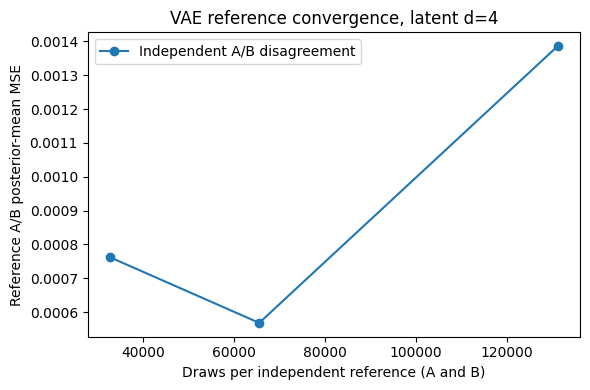

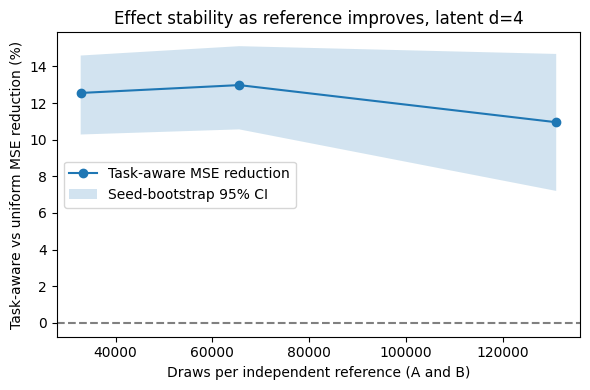

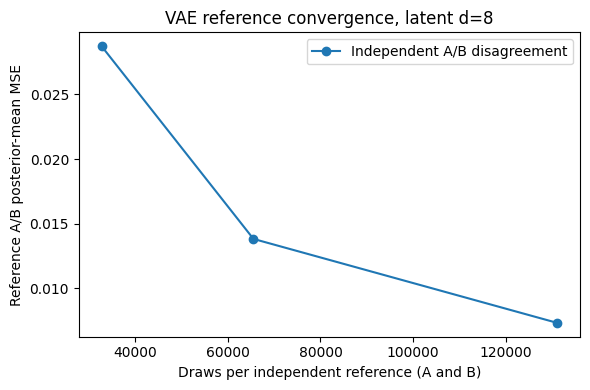

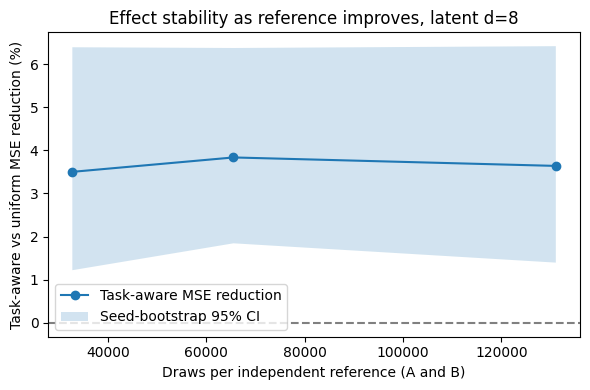

Results saved at: /content/drive/MyDrive/TaskAware_VAE_Confirmation/followup_full_3dde513c60c2/reference_convergence_pilot_51d5800e7e0c
Interpretation: declining A/B disagreement and stable effect estimates are encouraging,
but common proposal bias means these references are not exact posterior ground truth.
Pilot (5 seeds / 16 images) is diagnostic only; do NOT report its p-values in an SOP.


In [20]:
# REFERENCE-CONVERGENCE ADD-ON FOR Task_Aware_VAE_Followup_Colab.ipynb
# Paste this complete cell AFTER Section 15 (seed-level analysis).
# Does not retrain VAEs. Uses the saved checkpoints and the frozen, already-selected proposals.
# Important: run the notebook's SETUP/FUNCTION cells first so that FC, cfg, FUOUT, etc. exist.

import itertools
from dataclasses import asdict

# Choose "pilot" first. It processes 5 seeds / 16 held-out images per dimension.
# Once checked, change to "full" to run all 25 seeds / 104 held-out images per dimension.
REF_AUDIT_MODE = globals().get("REF_AUDIT_MODE", "pilot")   # "pilot" or "full"
REFERENCE_SIZES = (32_768, 65_536, 131_072)  # draws PER independent reference (A and B)
REFERENCE_BOOTSTRAPS = 5000

if REF_AUDIT_MODE not in ("pilot", "full"):
    raise ValueError("REF_AUDIT_MODE must be 'pilot' or 'full'")
if FOLLOWUP_MODE != "full":
    raise RuntimeError("This add-on is for the full VAE follow-up, not the smoke test")
if any(n <= 0 or n % FC.reference_chunk for n in REFERENCE_SIZES):
    raise ValueError("Reference sizes must be positive multiples of FC.reference_chunk")
if len(set(REFERENCE_SIZES)) != len(REFERENCE_SIZES):
    raise ValueError("Reference sizes must be unique")
N_LIST = tuple(sorted(REFERENCE_SIZES))
SEED_COUNT = 5 if REF_AUDIT_MODE == "pilot" else FC.n_seeds
IMAGE_COUNT = 16 if REF_AUDIT_MODE == "pilot" else len(x_follow)
# Deterministically chosen ONCE, independent of the experimental outcomes.
image_rng = np.random.default_rng(20261123)
IMAGE_IDS = np.sort(image_rng.choice(len(x_follow), IMAGE_COUNT, replace=False))
AUDIT_SPEC = {
    "audit_mode": REF_AUDIT_MODE, "N_each": list(N_LIST),
    "seeds": SEED_COUNT, "image_ids_within_x_follow": IMAGE_IDS.tolist(),
    "online_repeats": FC.online_repeats, "online_average": FC.online_average,
    "reference_chunk": FC.reference_chunk,
    "orig_fuout": str(FUOUT), "followup_config": asdict(FC)
}
AUDIT_HASH = hashlib.sha256(json.dumps(AUDIT_SPEC, sort_keys=True).encode()).hexdigest()[:12]
REF_AUDIT_OUT = FUOUT / f'reference_convergence_{REF_AUDIT_MODE}_{AUDIT_HASH}'
REF_AUDIT_OUT.mkdir(parents=True, exist_ok=True)
(REF_AUDIT_OUT / 'audit_config.json').write_text(json.dumps(AUDIT_SPEC, indent=2))
print('Mode:', REF_AUDIT_MODE, '| output:', REF_AUDIT_OUT)
print('Reference draws per independent pass:', N_LIST)
print('Training seeds per dimension:', SEED_COUNT, '| images per seed:', IMAGE_COUNT)

@torch.inference_mode()
def reference_checkpoints(model, images, rng_seed, proposal, checkpoints):
    """One pass to max N; return SNIS mu/logZ/ESS snapshots at each N.

    Image batches and log-sum-exp stabilization keep GPU memory bounded.
    Each call has independent random draws when its rng_seed differs.
    """
    nmax = max(checkpoints)
    snapshots = {n: {'mu': [], 'logz': [], 'ess': []} for n in checkpoints}
    g = torch_rng(rng_seed)
    for begin in range(0, len(images), FC.ref_image_batch):
        xb = images[begin:begin + FC.ref_image_batch]
        batch_n, d = len(xb), model.latent_dim
        maximum = torch.full((batch_n,), -float('inf'), dtype=torch.float64, device=DEVICE)
        sw = torch.zeros(batch_n, dtype=torch.float64, device=DEVICE)
        sw2 = torch.zeros(batch_n, dtype=torch.float64, device=DEVICE)
        swz = torch.zeros((batch_n, d), dtype=torch.float64, device=DEVICE)
        for first in range(0, nmax, FC.reference_chunk):
            draw_n = min(FC.reference_chunk, nmax - first)
            z, lw = draw_proposal(model, xb, draw_n, g, proposal)
            z, lw = z.double(), lw.double()
            nxt = torch.maximum(maximum, lw.max(dim=1).values)
            scale = torch.exp(maximum - nxt)
            w = torch.exp(lw - nxt[:, None])
            sw = sw * scale + w.sum(1)
            swz = swz * scale[:, None] + (w[:, :, None] * z).sum(1)
            sw2 = sw2 * scale.square() + w.square().sum(1)
            maximum = nxt
            processed = first + draw_n
            if processed in snapshots:
                snapshots[processed]['mu'].append((swz / sw[:, None]).cpu().numpy().copy())
                snapshots[processed]['logz'].append((maximum + sw.log() - math.log(processed)).cpu().numpy().copy())
                snapshots[processed]['ess'].append((sw.square() / sw2).cpu().numpy().copy())
    return {n: {key: np.concatenate(parts) for key, parts in record.items()}
            for n, record in snapshots.items()}

@torch.inference_mode()
def online_estimates_from_frozen_allocation(model, selected, regressors, seed, image_ids):
    """Replays the two selected-proposal methods with the ORIGINAL full-test group budgets.

    We only *score* image_ids; allocation and RNG generation still cover all 104 images.
    This avoids changing the original test protocol by using a smaller allocation group.
    """
    feats = get_features(model, x_follow)
    score = np.exp(regressors['Task512'].predict(feats)).clip(1e-8, 1e8)
    n = len(x_follow)
    k_uniform = np.empty(n, dtype=np.int32)
    k_task = np.empty(n, dtype=np.int32)
    for start in range(0, n, FC.group_size):
        end = start + FC.group_size
        total = FC.group_size * FC.online_average
        k_uniform[start:end] = bounded_allocate(
            np.ones(FC.group_size), total, cfg.k_min, cfg.k_max)
        k_task[start:end] = bounded_allocate(
            score[start:end], total, cfg.k_min, cfg.k_max)
    assert all(k_uniform[j:j+FC.group_size].sum() == FC.group_size * FC.online_average
               and k_task[j:j+FC.group_size].sum() == FC.group_size * FC.online_average
               for j in range(0,n,FC.group_size))
    arange = torch.arange(cfg.k_max, device=DEVICE)
    inds = torch.as_tensor(image_ids, device=DEVICE, dtype=torch.long)
    preds = {'SelectedUniform': [], 'SelectedTask512': []}
    for rep in range(FC.online_repeats):
        # Same random seeds, sample bank, and selected proposal as the main follow-up experiment.
        g = torch_rng(seed + 8_000_000 + rep)
        z, lw = draw_proposal(model, x_follow, cfg.k_max, g, selected)
        z, lw = z.double(), lw.double()
        for method, counts in [('SelectedUniform',k_uniform), ('SelectedTask512',k_task)]:
            ct = torch.as_tensor(counts, device=DEVICE, dtype=torch.long)
            mask = arange[None, :] < ct[:, None]
            w = torch.softmax(lw.masked_fill(~mask, -float('inf')), dim=1)
            mu = (w[:, :, None] * z).sum(1).index_select(0, inds)
            preds[method].append(mu.cpu().numpy())
    return {method: np.stack(arrays) for method, arrays in preds.items()}

def audit_one_seed(dim, seed, image_ids):
    prefix = FUOUT / f'd{dim}_s{seed}'
    complete = FUOUT / f'd{dim}_s{seed}.complete.json'
    weights_path = FUOUT / f'd{dim}_s{seed}.model.pt'
    regs_path = FUOUT / f'd{dim}_s{seed}.allocation_regressors.joblib'
    if not all(p.exists() for p in (complete, weights_path, regs_path)):
        raise FileNotFoundError(f'Missing existing model/results for d={dim}, seed={seed}. '
                                'Run the original full follow-up experiment first.')
    info = json.loads(complete.read_text())
    # The proposal is frozen from the EXISTING validation-based tuning, not retuned here.
    selected = next((p for p in PROPOSALS if p.name == info['proposal']), None)
    if selected is None:
        raise ValueError(f"Saved proposal {info['proposal']} is not in PROPOSALS")
    model = GaussianVAE(dim, cfg.hidden, cfg.decoder_sigma).to(DEVICE)
    try:
        try:
            state = torch.load(weights_path, map_location=DEVICE, weights_only=True)
        except TypeError:
            state = torch.load(weights_path, map_location=DEVICE)
        model.load_state_dict(state)
        model.eval()
        regs = joblib.load(regs_path)
        # Frozen online estimates do not depend on the reference size.
        online = online_estimates_from_frozen_allocation(model, selected, regs, seed, image_ids)
        xs = x_follow[image_ids]
        ref_A = reference_checkpoints(model, xs, seed + 31_000_000 + dim * 1000 + 1, selected, N_LIST)
        ref_B = reference_checkpoints(model, xs, seed + 31_000_000 + dim * 1000 + 2, selected, N_LIST)
        rows=[]
        combined={}
        for N in N_LIST:
            A, B = ref_A[N], ref_B[N]
            R = combine_references(A,B)
            combined[N] = R['mu']
            ess_fraction = R['ess']/(2*N)
            row={'dim':dim,'seed':seed,'reference_N_each':N,
                 'n_audit_images':len(xs),'selected_proposal':selected.name,
                 'ref_pair_mse':float(np.mean((A['mu']-B['mu'])**2)),
                 'ref_ess_fraction_median':float(np.median(ess_fraction)),
                 'ref_ess_below_1pct':float(np.mean(ess_fraction < 0.01)),
                 'reference_evaluations':int(len(xs)*2*N)}
            for label, target in [('combined',R['mu']),('A',A['mu']),('B',B['mu'])]:
                uniform_mse=float(np.mean((online['SelectedUniform']-target[None,:,:])**2))
                task_mse=float(np.mean((online['SelectedTask512']-target[None,:,:])**2))
                row[f'uniform_mse_{label}']=uniform_mse
                row[f'task_mse_{label}']=task_mse
                row[f'paired_difference_{label}']=task_mse-uniform_mse
                row[f'reduction_pct_{label}']=100*(1-task_mse/uniform_mse)
            rows.append(row)
        for i, row in enumerate(rows):
            previous_N = N_LIST[i-1] if i > 0 else None
            row['ref_change_from_previous_mse']=(
                float(np.mean((combined[row['reference_N_each']]-combined[previous_N])**2))
                if previous_N is not None else np.nan)
        return pd.DataFrame(rows)
    finally:
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# Checkpoint one seed at a time. Re-run this cell after a Colab interruption to resume.
for dim in FC.dims:
    for i in range(SEED_COUNT):
        seed = FC.seed_start + i
        dest = REF_AUDIT_OUT / f'd{dim}_s{seed}.audit.csv'
        if dest.exists():
            print(f'Skipping completed audit d={dim}, seed={seed}')
            continue
        result = audit_one_seed(dim, seed, IMAGE_IDS)
        result.to_csv(dest, index=False)
        print(f'Completed d={dim}, seed={seed}: '
              f'pair MSE {result.ref_pair_mse.iloc[0]:.4g} -> '
              f'{result.ref_pair_mse.iloc[-1]:.4g}; '
              f'full-N reduction {result.reduction_pct_combined.iloc[-1]:+.3f}%')

# Aggregate only the completed seeds; report missing seeds explicitly.
parts = [pd.read_csv(p) for p in sorted(REF_AUDIT_OUT.glob('d*_s*.audit.csv'))]
if not parts:
    raise RuntimeError('No completed audits to summarize')
AUDIT = pd.concat(parts,ignore_index=True)
AUDIT.to_csv(REF_AUDIT_OUT/'all_seed_reference_convergence.csv',index=False)
print('Completed seed counts:',AUDIT[AUDIT.reference_N_each==N_LIST[-1]].groupby('dim').seed.nunique().to_dict())

summary_rows=[]
rng=np.random.default_rng(333)
for (dim,N), g in AUDIT.groupby(['dim','reference_N_each'], sort=True):
    x=g['task_mse_combined'].to_numpy()
    y=g['uniform_mse_combined'].to_numpy()
    d=x-y
    n=len(d)
    diff=float(np.mean(d))
    if n>1:
        half=stats.t.ppf(.975,n-1)*stats.sem(d)
        ci_low,ci_high=diff-half,diff+half
        ids=rng.integers(0,n,size=(REFERENCE_BOOTSTRAPS,n))
        boot_reductions=100*(1-x[ids].mean(1)/y[ids].mean(1))
        pct_lo,pct_hi=np.quantile(boot_reductions,[.025,.975])
        # Exact two-sided sign flip at n<=16; otherwise Monte Carlo.
        if n<=16:
            flips=np.asarray(list(itertools.product((-1.,1.),repeat=n)))
        else:
            flips=rng.choice((-1.,1.),size=(100_000,n))
        p=float(np.mean(np.abs((flips*d).mean(1))>=abs(diff)-1e-15))
    else:
        ci_low=ci_high=pct_lo=pct_hi=p=np.nan
    summary_rows.append({'dim':dim,'reference_N_each':int(N), 'n_seeds':n,
        'mean_reference_pair_mse':g.ref_pair_mse.mean(),
        'mean_reference_change_mse':g.ref_change_from_previous_mse.mean(),
        'median_reference_ess_fraction':g.ref_ess_fraction_median.median(),
        'mean_ref_fraction_below_1pct':g.ref_ess_below_1pct.mean(),
        'mean_task_mse':x.mean(),'mean_uniform_mse':y.mean(),
        'paired_difference':diff,'paired_ci_low':ci_low,'paired_ci_high':ci_high,
        'mse_reduction_pct':100*(1-x.mean()/y.mean()),
        'reduction_bootstrap_ci_low':pct_lo,'reduction_bootstrap_ci_high':pct_hi,
        'paired_signflip_p':p,'seeds_task_lower':int((d<0).sum()),
        'reduction_ref_A_pct':100*(1-g.task_mse_A.mean()/g.uniform_mse_A.mean()),
        'reduction_ref_B_pct':100*(1-g.task_mse_B.mean()/g.uniform_mse_B.mean())})
SUMMARY=pd.DataFrame(summary_rows).sort_values(['dim','reference_N_each'])
SUMMARY.to_csv(REF_AUDIT_OUT/'reference_convergence_summary.csv',index=False)
print('\nREFERENCE CONVERGENCE SUMMARY (exploratory until full 25 seeds / 104 images):')
display(SUMMARY.round(6))

for dim in sorted(SUMMARY.dim.unique()):
    s=SUMMARY[SUMMARY.dim==dim]
    fig,ax=plt.subplots(figsize=(6,4))
    ax.plot(s.reference_N_each,s.mean_reference_pair_mse,'o-',label='Independent A/B disagreement')
    ax.set_xlabel('Draws per independent reference (A and B)')
    ax.set_ylabel('Reference A/B posterior-mean MSE')
    ax.set_title(f'VAE reference convergence, latent d={dim}')
    ax.legend()
    fig.tight_layout()
    fig.savefig(REF_AUDIT_OUT/f'd{dim}_reference_convergence.png',dpi=160)
    plt.show()
    fig,ax=plt.subplots(figsize=(6,4))
    ax.plot(s.reference_N_each,s.mse_reduction_pct,'o-',label='Task-aware MSE reduction')
    ax.fill_between(s.reference_N_each,s.reduction_bootstrap_ci_low,
                    s.reduction_bootstrap_ci_high,alpha=.2,label='Seed-bootstrap 95% CI')
    ax.axhline(0,linestyle='--',color='grey')
    ax.set_xlabel('Draws per independent reference (A and B)')
    ax.set_ylabel('Task-aware vs uniform MSE reduction (%)')
    ax.set_title(f'Effect stability as reference improves, latent d={dim}')
    ax.legend()
    fig.tight_layout()
    fig.savefig(REF_AUDIT_OUT/f'd{dim}_effect_stability.png',dpi=160)
    plt.show()

print('Results saved at:',REF_AUDIT_OUT)
print('Interpretation: declining A/B disagreement and stable effect estimates are encouraging,')
print('but common proposal bias means these references are not exact posterior ground truth.')
print('Pilot (5 seeds / 16 images) is diagnostic only; do NOT report its p-values in an SOP.')


Mode: full 
Outputs: /content/drive/MyDrive/TaskAware_VAE_Confirmation/followup_full_3dde513c60c2/independent_posterior_checks_full
TEST 1: repeating 4D seed 27000 independent high-budget reference pairs...
4D seed 27000 stream original: A/B MSE 0.00537672; max single-image MSE 0.080276
4D seed 27000 stream 1/3: A/B MSE 0.000593755; max single-image MSE 0.00591658
4D seed 27000 stream 2/3: A/B MSE 0.00626482; max single-image MSE 0.0951086
4D seed 27000 stream 3/3: A/B MSE 0.000547438; max single-image MSE 0.00745939


,replicate_pair,image_id,pair_mse,A_ess_fraction,B_ess_fraction,A_max_weight_share,B_max_weight_share,A_top10_weight_share,B_top10_weight_share
47,1,102,0.095109,0.004193,0.000029,0.017044,0.384256,0.100019,0.769082
11,-1,81,0.080276,0.000105,0.000011,0.237780,0.831730,0.501093,0.868262
63,2,102,0.007459,0.000103,0.000457,0.228062,0.090267,0.500885,0.262322
30,0,99,0.005917,0.003799,0.000760,0.023943,0.084436,0.107719,0.211807
15,-1,102,0.004060,0.004344,0.000346,0.013288,0.103774,0.095296,0.318175
43,1,81,0.002009,0.001933,0.000560,0.037347,0.088605,0.151041,0.280139
46,1,99,0.001749,0.004274,0.001180,0.018618,0.074474,0.109287,0.136135
31,0,102,0.001575,0.000308,0.000422,0.141610,0.119377,0.296869,0.266019
14,-1,99,0.001088,0.002644,0.003237,0.027507,0.032507,0.137384,0.109189
41,1,69,0.000808,0.000887,0.001991,0.062729,0.050826,0.223902,0.129191


,pair_mse,worst_image_mse,max_A_weight,max_B_weight
replicate_pair,,,,
-1,0.005377,0.080276,0.237780,0.831730
0,0.000594,0.005917,0.141610,0.119377
1,0.006265,0.095109,0.062729,0.384256
2,0.000547,0.007459,0.228062,0.090267


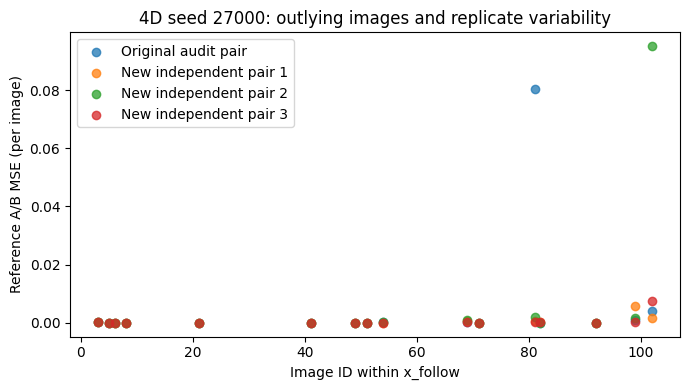

TEST 2: independent 8D posterior cross-check with multiple-chain HMC...
8D seed 27000, img 3: rhat=1.004; ESS_min=602; HMC diagnostics PASS=True; IS(A)/HMC MSE=0.001266
8D seed 27000, img 5: rhat=1.005; ESS_min=867; HMC diagnostics PASS=True; IS(A)/HMC MSE=0.000387
8D seed 27000, img 6: rhat=1.006; ESS_min=770; HMC diagnostics PASS=True; IS(A)/HMC MSE=0.0006541
8D seed 27002, img 3: rhat=1.006; ESS_min=615; HMC diagnostics PASS=True; IS(A)/HMC MSE=0.0006127
8D seed 27002, img 5: rhat=1.004; ESS_min=1130; HMC diagnostics PASS=True; IS(A)/HMC MSE=0.001146
8D seed 27002, img 6: rhat=1.005; ESS_min=873; HMC diagnostics PASS=True; IS(A)/HMC MSE=0.0002816


,seed,image_id,max_rank_rhat,min_bulk_ess,accept_mean,large_energy_errors,passed_basic_diagnostics,A_vs_B_mse,A_vs_HMC_mse,B_vs_HMC_mse
0,27000,3,1.003760,602.410059,0.835125,0,True,0.002351,0.001266,0.002780
1,27000,5,1.005461,867.429707,0.830125,0,True,0.000202,0.000387,0.000157
2,27000,6,1.005913,769.583774,0.824375,0,True,0.000172,0.000654,0.000460
3,27002,3,1.006260,615.031671,0.819250,0,True,0.000197,0.000613,0.000803
4,27002,5,1.003680,1130.250692,0.829250,0,True,0.003239,0.001146,0.001392
5,27002,6,1.004574,873.016890,0.821500,0,True,0.000625,0.000282,0.001337



SAVED: /content/drive/MyDrive/TaskAware_VAE_Confirmation/followup_full_3dde513c60c2/independent_posterior_checks_full
Quick mode is a CODE CHECK ONLY. Full mode is a small diagnostic, not a population-wide confirmation.
HMC comparisons must NOT be interpreted when R-hat/ESS/energy diagnostics fail.


In [22]:
"""Independent reference-weight diagnostics and HMC cross-check.

Run with %run -i /content/VAE_Posterior_Reference_Diagnostics_Addon.py
AFTER the original Task_Aware_VAE_Followup_With_Reference_Audit notebook
has defined its VAE/proposal utilities and FUOUT, x_follow, cfg, etc.
No model training is performed by this add-on.
"""
import math, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

if 'FUOUT' not in globals() or 'x_follow' not in globals() or 'GaussianVAE' not in globals():
    raise RuntimeError('Run the VAE follow-up notebook setup/function cells first (FUOUT, x_follow, GaussianVAE are required).')
if 'FC' not in globals() or 'PROPOSALS' not in globals() or 'draw_proposal' not in globals():
    raise RuntimeError('Run the notebook through its follow-up setup before this add-on.')
if FOLLOWUP_MODE != 'full':
    raise RuntimeError('This audit requires the existing FULL follow-up run, not smoke-mode weights.')

CHECK_MODE = "full"  # 'quick' for smoke, 'full' for evidence
if CHECK_MODE not in ('quick','full'):
    raise ValueError('CHECK_MODE must be quick or full')

# This matches the original reference audit's deterministic pilot image selection.
if 'IMAGE_IDS' in globals() and len(IMAGE_IDS) == 16:
    _IMAGE_IDS = np.asarray(IMAGE_IDS, dtype=np.int64)
else:
    _IMAGE_IDS = np.sort(np.random.default_rng(20261123).choice(len(x_follow),16,replace=False))

REF_REPEATS = 1 if CHECK_MODE == 'quick' else 3
REF_N = 4096 if CHECK_MODE == 'quick' else 131_072
REF_IMAGE_IDS = _IMAGE_IDS[:2] if CHECK_MODE == 'quick' else _IMAGE_IDS
HMC_SEEDS = [27000] if CHECK_MODE == 'quick' else [27000, 27002]
HMC_IMAGE_IDS = _IMAGE_IDS[:1] if CHECK_MODE == 'quick' else _IMAGE_IDS[:3]
HMC_CHAINS = 4
HMC_WARMUP = 80 if CHECK_MODE == 'quick' else 1000
HMC_DRAWS = 120 if CHECK_MODE == 'quick' else 2000
HMC_LF_STEPS = 12
HMC_REF_N = 4096 if CHECK_MODE == 'quick' else 131_072

OUT_DIAG = FUOUT / ('independent_posterior_checks_' + CHECK_MODE)
OUT_DIAG.mkdir(parents=True, exist_ok=True)
(OUT_DIAG / 'configuration.json').write_text(json.dumps({
    'mode':CHECK_MODE,'reference_repeats':REF_REPEATS,'reference_draws_each':REF_N,
    '4d_seed':27000,'reference_image_ids':REF_IMAGE_IDS.tolist(),
    'hmc_seeds':HMC_SEEDS,'hmc_image_ids':HMC_IMAGE_IDS.tolist(),
    'hmc_warmup':HMC_WARMUP,'hmc_samples_per_chain':HMC_DRAWS,
    'hmc_chains':HMC_CHAINS,'hmc_leapfrog_steps':HMC_LF_STEPS,
    'hmc_ref_draws_each':HMC_REF_N},indent=2))
print('Mode:',CHECK_MODE,'\nOutputs:',OUT_DIAG)


def _load_model_and_proposal(dim,seed,dtype=torch.float32):
    complete = FUOUT / f'd{dim}_s{seed}.complete.json'
    weights = FUOUT / f'd{dim}_s{seed}.model.pt'
    if not complete.exists() or not weights.exists():
        raise FileNotFoundError('Missing trained model for '+str((dim,seed))+'. Check that FUOUT points to the completed follow-up run and Drive is mounted if used.')
    saved = json.loads(complete.read_text())
    proposal = next((p for p in PROPOSALS if p.name == saved['proposal']),None)
    if proposal is None:
        raise ValueError('Saved proposal is not defined: '+saved['proposal'])
    model = GaussianVAE(dim,cfg.hidden,cfg.decoder_sigma).to(DEVICE)
    try:
        state=torch.load(weights,map_location=DEVICE,weights_only=True)
    except TypeError:
        state=torch.load(weights,map_location=DEVICE)
    model.load_state_dict(state)
    model=model.to(dtype=dtype).eval()
    for p in model.parameters(): p.requires_grad_(False)
    return model,proposal


@torch.inference_mode()
def detailed_reference_pass(model,xs,seed,proposal,N,chunk=1024):
    """Independent SNIS reference with per-image ESS, maximum weight share and top-10 mass.

    Uses exactly the notebook's draw_proposal (correct q mixture density).
    All accumulation is in float64 and streaming/logsumexp stabilized.
    """
    g=torch_rng(seed)
    chunks={k:[] for k in ('mu','ess','logz','max_weight_share','top10_weight_share')}
    d=model.latent_dim
    for start in range(0,len(xs),FC.ref_image_batch):
        xb=xs[start:start+FC.ref_image_batch]
        b=len(xb)
        lm=torch.full((b,),-float('inf'),dtype=torch.float64,device=DEVICE)
        sw=torch.zeros(b,dtype=torch.float64,device=DEVICE)
        sw2=torch.zeros(b,dtype=torch.float64,device=DEVICE)
        swz=torch.zeros((b,d),dtype=torch.float64,device=DEVICE)
        top=torch.full((b,10),-float('inf'),dtype=torch.float64,device=DEVICE)
        for first in range(0,N,chunk):
            take=min(chunk,N-first)
            z,lw=draw_proposal(model,xb,take,g,proposal)
            z,lw=z.double(),lw.double()
            new_lm=torch.maximum(lm,lw.max(1).values)
            rescale=torch.exp(lm-new_lm)
            w=torch.exp(lw-new_lm[:,None])
            sw=sw*rescale+w.sum(1)
            sw2=sw2*rescale.square()+(w*w).sum(1)
            swz=swz*rescale[:,None]+(w[:,:,None]*z).sum(1)
            lm=new_lm
            top=torch.topk(torch.cat((top,lw),axis=1),10,dim=1).values
        log_sw=lm+torch.log(sw)
        chunks['mu'].append((swz/sw[:,None]).cpu().numpy())
        chunks['ess'].append((sw.square()/sw2).cpu().numpy())
        chunks['logz'].append((log_sw-math.log(N)).cpu().numpy())
        chunks['max_weight_share'].append(torch.exp(top[:,0]-log_sw).cpu().numpy())
        chunks['top10_weight_share'].append(torch.exp(top-log_sw[:,None]).sum(1).cpu().numpy())
    return {k:np.concatenate(v) for k,v in chunks.items()}


def investigate_4d_seed():
    dim,seed=4,27000
    model,selected=_load_model_and_proposal(dim,seed)
    images=x_follow[REF_IMAGE_IDS]
    lines=[]
    seed_pairs=[]
    if CHECK_MODE == 'full':
        # Reproduce the anomalous 4D 131072-draw pair from the preceding audit.
        original_seed=seed+31_000_000+dim*1000
        seed_pairs.append((-1,original_seed+1,original_seed+2))
    seed_pairs.extend((rep,seed+55_000_001+rep*101,seed+55_000_002+rep*101)
                      for rep in range(REF_REPEATS))
    for rep,sA,sB in seed_pairs:
        A=detailed_reference_pass(model,images,sA,selected,REF_N)
        B=detailed_reference_pass(model,images,sB,selected,REF_N)
        per_img=np.mean((A['mu']-B['mu'])**2,axis=1)
        for j,image_id in enumerate(REF_IMAGE_IDS):
            lines.append({'dim':dim,'seed':seed,'replicate_pair':rep,'image_id':int(image_id),
                'dataset_index':int(fresh_ids[image_id]) if 'fresh_ids' in globals() else np.nan,
                'proposal':selected.name,'N_per_pass':REF_N,
                'reference_stream':('original' if rep==-1 else f'new_{rep+1}'),
                'pair_mse':float(per_img[j]),
                'A_ess_fraction':float(A['ess'][j]/REF_N),'B_ess_fraction':float(B['ess'][j]/REF_N),
                'A_max_weight_share':float(A['max_weight_share'][j]),
                'B_max_weight_share':float(B['max_weight_share'][j]),
                'A_top10_weight_share':float(A['top10_weight_share'][j]),
                'B_top10_weight_share':float(B['top10_weight_share'][j]),
                'A_logZ':float(A['logz'][j]),'B_logZ':float(B['logz'][j]),
                'A_posterior_mean':json.dumps(A['mu'][j].tolist()),
                'B_posterior_mean':json.dumps(B['mu'][j].tolist())})
        print(f'4D seed {seed} stream {"original" if rep==-1 else str(rep+1)+"/"+str(REF_REPEATS)}: A/B MSE {per_img.mean():.6g}; '
              f'max single-image MSE {per_img.max():.6g}')
    df=pd.DataFrame(lines)
    df.to_csv(OUT_DIAG/'4d_seed27000_reference_weight_diagnostics.csv',index=False)
    ranked=df.sort_values('pair_mse',ascending=False)
    display(ranked[['replicate_pair','image_id','pair_mse','A_ess_fraction','B_ess_fraction',
                    'A_max_weight_share','B_max_weight_share','A_top10_weight_share','B_top10_weight_share']].head(15))
    by_pair=df.groupby('replicate_pair').agg(pair_mse=('pair_mse','mean'),
       worst_image_mse=('pair_mse','max'),max_A_weight=('A_max_weight_share','max'),
       max_B_weight=('B_max_weight_share','max'))
    display(by_pair)
    fig,ax=plt.subplots(figsize=(7,4))
    for rep,part in df.groupby('replicate_pair'):
        label='Original audit pair' if rep==-1 else f'New independent pair {rep+1}'
        ax.scatter(part.image_id,part.pair_mse,label=label,alpha=.75)
    ax.set_xlabel('Image ID within x_follow');ax.set_ylabel('Reference A/B MSE (per image)')
    ax.set_title('4D seed 27000: outlying images and replicate variability')
    ax.legend();fig.tight_layout();fig.savefig(OUT_DIAG/'4d_outlier_reference_pairs.png',dpi=160);plt.show()
    return df


def _potential_and_grad(model,x,z):
    """U(z)=-log p(z,x), up to additive constants; exact Gaussian VAE decoder likelihood."""
    z=z.detach().requires_grad_(True)
    with torch.enable_grad():
        rec=model.decoder(z)
        U=.5*z.square().sum(-1)+.5*((x[None,:]-rec)/model.decoder_sigma).square().sum(-1)
        g=torch.autograd.grad(U.sum(),z)[0]
    return U.detach(),g.detach()


def run_fixed_length_hmc(model,x,seed,chains=4,warmup=1000,n_draws=2000,n_leapfrog=12,
                         initial_step=.02,target_accept=.82):
    """Four independent chains, leapfrog, Metropolis correction, dual-averaging step-size adaptation.

    This is a deliberately small independent posterior cross-check, NOT a substitute for NUTS.
    Require R-hat / bulk ESS diagnostics before using samples for scientific conclusions.
    """
    x=x.to(DEVICE,dtype=torch.float64)
    generator=torch.Generator(device=DEVICE.type)
    generator.manual_seed(int(seed))
    with torch.no_grad():
        enc_mu,enc_lv=model.encode(x[None,:])
        starts=enc_mu+torch.exp(.5*enc_lv)*torch.randn((chains,model.latent_dim),
                                                      generator=generator,device=DEVICE,dtype=torch.float64)
    q=starts.detach()
    eps=float(initial_step)
    da_mu=np.log(10*eps);da_logepsbar=np.log(eps);da_H=0.0
    accepted=[];integration_errors=[];draws=[]
    for t in range(1,warmup+n_draws+1):
        p0=torch.randn(q.shape,device=DEVICE,dtype=torch.float64,generator=generator)
        U0,g0=_potential_and_grad(model,x,q)
        q1=q.clone();p=p0-.5*eps*g0
        for l in range(n_leapfrog):
            q1=q1+eps*p
            U1,g1=_potential_and_grad(model,x,q1)
            if l+1<n_leapfrog:p=p-eps*g1
        p=p-.5*eps*g1
        delta=(U0+.5*p0.square().sum(-1))-(U1+.5*p.square().sum(-1))
        delta=torch.nan_to_num(delta,nan=-1e10,posinf=-1e10,neginf=-1e10)
        acceptprob=torch.exp(torch.minimum(delta,torch.zeros_like(delta))).clamp(0,1)
        change=torch.rand((chains,),device=DEVICE,generator=generator)<acceptprob
        q=torch.where(change[:,None],q1,q).detach()
        if t<=warmup:
            # One shared step size, adapted from average accept probability.
            a=float(acceptprob.mean())
            weight=1.0/(t+10)
            da_H=(1-weight)*da_H+weight*(target_accept-a)
            logeps=da_mu-math.sqrt(t)/.05*da_H
            logeps=min(max(logeps,math.log(1e-4)),math.log(.3))
            power=t**(-.75)
            da_logepsbar=power*logeps+(1-power)*da_logepsbar
            eps=math.exp(logeps)
            if t==warmup:
                eps=float(np.clip(math.exp(da_logepsbar),1e-4,.3))
        else:
            accepted.append(change.cpu().numpy())
            integration_errors.append((delta.abs()>100).cpu().numpy())
            draws.append(q.cpu().numpy().copy())
    sample_array=np.stack(draws).transpose(1,0,2)   # (chain,draw,dimension)
    acc=np.stack(accepted).mean(axis=0)
    div=np.stack(integration_errors).sum(axis=0)
    return sample_array,{'step_size':eps,'accept_fraction_by_chain':acc.tolist(),
                         'large_energy_error_by_chain':div.tolist()}


def hmc_diagnostics(draws,info):
    import arviz as az
    # Array API works across ArviZ releases (including >=1.0).
    rhat=np.asarray([float(az.rhat(draws[:,:,j],method='rank')) for j in range(draws.shape[-1])])
    ess=np.asarray([float(az.ess(draws[:,:,j],method='bulk')) for j in range(draws.shape[-1])])
    mu=draws.mean(axis=(0,1))
    # approximate marginal Monte Carlo SE using bulk ESS (not a joint confidence region)
    sd=draws.reshape(-1,draws.shape[-1]).std(axis=0,ddof=1)
    mcse=sd/np.sqrt(np.maximum(ess,1))
    valid=(np.isfinite(rhat).all() and np.isfinite(ess).all()
           and rhat.max()<1.01 and ess.min()>400
           and not any(x>0 for x in info['large_energy_error_by_chain'])
           and np.min(info['accept_fraction_by_chain'])>.5)
    return dict(mu=mu,mcse=mcse,max_rank_rhat=float(rhat.max()),
         min_bulk_ess=float(ess.min()),accept_mean=float(np.mean(info['accept_fraction_by_chain'])),
         large_energy_errors=int(sum(info['large_energy_error_by_chain'])),
         passed_basic_diagnostics=bool(valid))


def investigate_8d_hmc():
    try:
        import arviz
    except ImportError as exc:
        raise ImportError('ArviZ is required. In Colab, run !pip -q install arviz') from exc
    output=[]
    for seed in HMC_SEEDS:
        m_ref,selected=_load_model_and_proposal(8,seed)
        # Dedicated float64 decoder for gradient integration. IS uses original float32 weights.
        m_hmc,_=_load_model_and_proposal(8,seed,dtype=torch.float64)
        xs=x_follow[HMC_IMAGE_IDS]
        # Predictive baselines use the frozen original 104-image allocation groups.
        regs_path=FUOUT/f'd8_s{seed}.allocation_regressors.joblib'
        if regs_path.exists() and 'online_estimates_from_frozen_allocation' in globals():
            import joblib
            regs=joblib.load(regs_path)
            online=online_estimates_from_frozen_allocation(m_ref,selected,regs,seed,HMC_IMAGE_IDS)
        else:
            online=None
        refsA=detailed_reference_pass(m_ref,xs,seed+61_000_001,selected,HMC_REF_N)
        refsB=detailed_reference_pass(m_ref,xs,seed+61_000_002,selected,HMC_REF_N)
        for j,image_id in enumerate(HMC_IMAGE_IDS):
            casefile=OUT_DIAG/f'd8_seed{seed}_img{int(image_id)}.summary.json'
            if casefile.exists():
                r=json.loads(casefile.read_text())
                output.append(r)
                print(f'Skipping previously completed HMC case: seed={seed}, image={int(image_id)}')
                continue
            samp,details=run_fixed_length_hmc(m_hmc,xs[j],seed+70_000_000+int(image_id),
                   chains=HMC_CHAINS,warmup=HMC_WARMUP,n_draws=HMC_DRAWS,
                   n_leapfrog=HMC_LF_STEPS)
            d=hmc_diagnostics(samp,details)
            meanA=refsA['mu'][j];meanB=refsB['mu'][j]
            errorA=float(np.mean((meanA-d['mu'])**2))
            errorB=float(np.mean((meanB-d['mu'])**2))
            r={'dim':8,'seed':seed,'image_id':int(image_id),
               'selected_proposal':selected.name,'draws_per_IS_reference':HMC_REF_N,
               'A_vs_B_mse':float(np.mean((meanA-meanB)**2)),
               'A_vs_HMC_mse':errorA,'B_vs_HMC_mse':errorB,
               'A_ess_fraction':float(refsA['ess'][j]/HMC_REF_N),
               'B_ess_fraction':float(refsB['ess'][j]/HMC_REF_N),
               'A_max_weight_share':float(refsA['max_weight_share'][j]),
               'B_max_weight_share':float(refsB['max_weight_share'][j]),
               'hmc_mean':json.dumps(d['mu'].tolist()),
               'hmc_mcse':json.dumps(d['mcse'].tolist()),
               'IS_A_mean':json.dumps(meanA.tolist()),
               'IS_B_mean':json.dumps(meanB.tolist()),
               **{k:v for k,v in d.items() if k not in ('mu','mcse')},
               'hmc_step_size':details['step_size']}
            if online is not None:
                r['uniform_mse_vs_HMC']=float(np.mean((online['SelectedUniform'][:,j,:]-d['mu'])**2))
                r['task_mse_vs_HMC']=float(np.mean((online['SelectedTask512'][:,j,:]-d['mu'])**2))
            output.append(r)
            np.savez_compressed(OUT_DIAG/f'd8_seed{seed}_img{image_id}_HMC.npz',samples=samp)
            casefile.write_text(json.dumps(r, indent=2))
            print(f'8D seed {seed}, img {int(image_id)}: rhat={d["max_rank_rhat"]:.3f}; '
                  f'ESS_min={d["min_bulk_ess"]:.0f}; HMC diagnostics PASS={d["passed_basic_diagnostics"]}; '
                  f'IS(A)/HMC MSE={errorA:.4g}')
            pd.DataFrame(output).to_csv(OUT_DIAG/'8d_hmc_vs_IS_per_image.csv',index=False)
        del m_ref,m_hmc
        if torch.cuda.is_available():torch.cuda.empty_cache()
    df=pd.DataFrame(output)
    display(df[['seed','image_id','max_rank_rhat','min_bulk_ess','accept_mean',
               'large_energy_errors','passed_basic_diagnostics','A_vs_B_mse','A_vs_HMC_mse','B_vs_HMC_mse']])
    return df

print('TEST 1: repeating 4D seed 27000 independent high-budget reference pairs...')
D4_WEIGHT_AUDIT=investigate_4d_seed()
print('TEST 2: independent 8D posterior cross-check with multiple-chain HMC...')
D8_HMC_AUDIT=investigate_8d_hmc()
print('\nSAVED:',OUT_DIAG)
print('Quick mode is a CODE CHECK ONLY. Full mode is a small diagnostic, not a population-wide confirmation.')
print('HMC comparisons must NOT be interpreted when R-hat/ESS/energy diagnostics fail.')


DIRECT HMC allocation audit: full
Output: /content/drive/MyDrive/TaskAware_VAE_Confirmation/followup_full_3dde513c60c2/direct_hmc_allocation_full_4d2d32f5cd
8D seeds: [27002, 27003, 27008, 27011, 27015, 27018, 27020, 27022]
Image IDs within x_follow: [2, 19, 26, 34, 40, 44, 48, 65, 66, 71, 88, 90]
Online: exact original 52-image budgets, 12 matched repeats

8D seed 27002: loading frozen model, selected proposal, and online allocations
  image   2: pass=True, Rhat=1.0017, bulkESS=1148, Task−Uniform=-0.026909
  image  19: pass=True, Rhat=1.0082, bulkESS=589, Task−Uniform=+0.0040376
  image  26: pass=True, Rhat=1.0008, bulkESS=4912, Task−Uniform=-0.0021817
  image  34: pass=True, Rhat=1.0075, bulkESS=656, Task−Uniform=-0.0084605
  image  40: pass=True, Rhat=1.0057, bulkESS=643, Task−Uniform=-0.0016641
  image  44: pass=True, Rhat=1.0032, bulkESS=1920, Task−Uniform=+0.017004
  image  48: pass=True, Rhat=1.0033, bulkESS=2022, Task−Uniform=+0.0066227
  image  65: pass=True, Rhat=1.0045, bulk

,seed,attempted,passed,max_rhat,min_ess,pass_fraction
0,27002,12,12,1.008175,589.136346,1.000000
1,27003,12,11,1.015228,461.157963,0.916667
2,27008,12,12,1.009112,470.611062,1.000000
3,27011,12,12,1.005523,779.320834,1.000000
4,27015,12,12,1.007533,601.789240,1.000000
5,27018,12,12,1.007007,519.025914,1.000000
6,27020,12,11,1.010713,518.860250,0.916667
7,27022,12,11,1.008330,371.289002,0.916667



HMC reference coverage: 93/96 (96.9%)
Seeds with >=6 passing HMC images: 8
Meets prespecified coverage rule: True

Per-seed comparison (only diagnostically passing HMC references):


,seed,n_hmc_passed,HMC_uniform_mse,HMC_task_mse,HMC_chains12_uniform_mse,HMC_chains12_task_mse,HMC_chains34_uniform_mse,HMC_chains34_task_mse,Original_IS_uniform_mse,Original_IS_task_mse
0,27002,12,0.126461,0.125599,0.125361,0.124609,0.127678,0.126706,0.133048,0.131966
1,27003,11,0.084068,0.082751,0.083641,0.082334,0.084564,0.083238,0.082781,0.081675
2,27008,12,0.109231,0.102307,0.106798,0.100056,0.111867,0.104760,0.111644,0.104748
3,27011,12,0.125930,0.130886,0.125962,0.130943,0.126026,0.130959,0.123481,0.128705
4,27015,12,0.117461,0.118965,0.116826,0.118779,0.118300,0.119355,0.101524,0.103487
5,27018,12,0.177288,0.183026,0.176996,0.182545,0.177698,0.183626,0.191100,0.198046
6,27020,11,0.165850,0.160470,0.164813,0.159399,0.167003,0.161656,0.153275,0.146568
7,27022,11,0.078903,0.076311,0.079091,0.076591,0.078787,0.076103,0.080119,0.078240



Effect estimates and seed-level uncertainty:


,reference,n_seeds,mean_uniform_mse,mean_task_mse,paired_difference_task_minus_uniform,paired_t95ci_low,paired_t95ci_high,relative_reduction_percent,reduction_bootstrap_ci_low,reduction_bootstrap_ci_high,exact_two_sided_signflip_p,seeds_task_lower
0,HMC,8,0.123149,0.122539,-0.000610,-0.004387,0.003168,0.494932,-1.775706,2.966310,0.695312,5
1,HMC_chains12,8,0.122436,0.121907,-0.000529,-0.004274,0.003216,0.431911,-1.825718,2.913927,0.734375,5
2,HMC_chains34,8,0.123990,0.123300,-0.000690,-0.004505,0.003125,0.556651,-1.712331,3.004979,0.656250,5
3,Original_IS,8,0.122121,0.121679,-0.000442,-0.004637,0.003753,0.361909,-2.153915,3.107628,0.773438,5


HMC comparison is an exploratory subset, NOT a new preregistered confirmation.


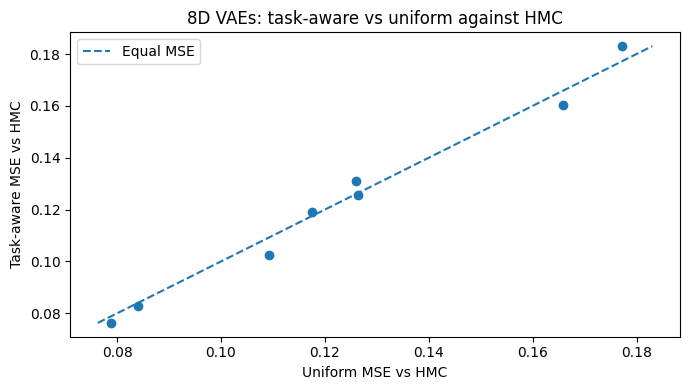


Saved output: /content/drive/MyDrive/TaskAware_VAE_Confirmation/followup_full_3dde513c60c2/direct_hmc_allocation_full_4d2d32f5cd


In [24]:
"""Direct, independent HMC posterior-mean comparison for the existing VAE follow-up.

Paste this code as ONE new cell in Task_Aware_VAE_Followup_Colab (1).ipynb
AFTER the existing independent HMC diagnostic cell (which defines
run_fixed_length_hmc, hmc_diagnostics, _load_model_and_proposal) and AFTER
Section 15A (which defines online_estimates_from_frozen_allocation).

The executed Colab cells must point FUOUT at the existing FULL follow-up
checkpoints.  This add-on NEVER refits a VAE or a sampling-difficulty regressor.
"""
import json, hashlib, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import joblib
from scipy import stats
from IPython.display import display

DIRECT_HMC_MODE = "full" # 'pilot' or 'full'
if DIRECT_HMC_MODE not in ('pilot', 'full'):
    raise ValueError('DIRECT_HMC_MODE must be pilot or full')
for required in ['FUOUT', 'FC', 'cfg', 'x_follow', 'DEVICE',
                 'run_fixed_length_hmc', 'hmc_diagnostics',
                 '_load_model_and_proposal',
                 'online_estimates_from_frozen_allocation']:
    if required not in globals():
        raise RuntimeError(f'Missing {required}: run the notebook setup, Section 15A, and the earlier HMC diagnostic cell first.')
if FOLLOWUP_MODE != 'full' or len(x_follow) != 104 or 8 not in FC.dims:
    raise RuntimeError('This add-on requires the completed FULL 8D VAE follow-up, with 104 frozen held-out images.')

# Frozen design; the seeds/images are selected without examining HMC allocation results.
# We exclude the three indices used in the previous 8D HMC diagnostic.
_PREVIOUS_HMC_IDS = np.sort(np.random.default_rng(20261123).choice(len(x_follow), 16, replace=False))[:3]
_rng_design = np.random.default_rng(20261124)
_ALL_SEEDS = sorted(int(v) for v in _rng_design.choice(
    np.arange(FC.seed_start, FC.seed_start + FC.n_seeds), size=8, replace=False))
_ELIGIBLE_IMAGE_IDS = np.array([i for i in range(len(x_follow))
                                if i not in set(_PREVIOUS_HMC_IDS.tolist())], dtype=int)
_ALL_IMAGE_IDS = sorted(int(v) for v in _rng_design.choice(_ELIGIBLE_IMAGE_IDS,
                                                             size=12, replace=False))
# The pilot is a code check only; do not combine its metrics with full-mode results.
HMC_AUDIT_SEEDS = _ALL_SEEDS[:1] if DIRECT_HMC_MODE == 'pilot' else _ALL_SEEDS
HMC_AUDIT_IMAGE_IDS = _ALL_IMAGE_IDS[:2] if DIRECT_HMC_MODE == 'pilot' else _ALL_IMAGE_IDS
HMC_AUDIT_WARMUP = 80 if DIRECT_HMC_MODE == 'pilot' else 1000
HMC_AUDIT_DRAWS = 120 if DIRECT_HMC_MODE == 'pilot' else 2000
HMC_AUDIT_CHAINS = 4
HMC_AUDIT_LF = 12
HMC_REQUIRED_PASS_FRACTION = 0.80  # prespecified coverage threshold for reporting aggregate comparisons
HMC_REQUIRED_MIN_PASS_PER_SEED = 6 # of the twelve images per seed in full mode

_AUDIT_CONFIG = {
    'mode': DIRECT_HMC_MODE, 'seeds': HMC_AUDIT_SEEDS,
    'image_ids': HMC_AUDIT_IMAGE_IDS,
    'excluded_previously_inspected_image_ids': _PREVIOUS_HMC_IDS.tolist(),
    'image_selection_seed': 20261124,
    'chains': HMC_AUDIT_CHAINS, 'warmup': HMC_AUDIT_WARMUP,
    'samples_per_chain': HMC_AUDIT_DRAWS, 'leapfrog_steps': HMC_AUDIT_LF,
    'online_repeats': FC.online_repeats, 'online_average_budget': FC.online_average,
    'original_group_size': FC.group_size,
    'max_draws_per_image_in_online_bank': cfg.k_max,
    'pass_fraction_required': HMC_REQUIRED_PASS_FRACTION,
    'min_pass_per_seed': HMC_REQUIRED_MIN_PASS_PER_SEED,
    'interpretation': 'exploratory subset chosen after inspecting earlier follow-up results'
}
_audit_hash = hashlib.sha256(json.dumps(_AUDIT_CONFIG,sort_keys=True).encode()).hexdigest()[:10]
HMC_AUDIT_DIR = FUOUT / f'direct_hmc_allocation_{DIRECT_HMC_MODE}_{_audit_hash}'
HMC_AUDIT_DIR.mkdir(parents=True,exist_ok=True)
_config_path = HMC_AUDIT_DIR / 'frozen_design.json'
if _config_path.exists() and json.loads(_config_path.read_text()) != _AUDIT_CONFIG:
    raise RuntimeError('Frozen configuration changed for an existing run directory.')
_config_path.write_text(json.dumps(_AUDIT_CONFIG,indent=2))
print('DIRECT HMC allocation audit:', DIRECT_HMC_MODE)
print('Output:', HMC_AUDIT_DIR)
print('8D seeds:', HMC_AUDIT_SEEDS)
print('Image IDs within x_follow:', HMC_AUDIT_IMAGE_IDS)
print('Online: exact original 52-image budgets,', FC.online_repeats, 'matched repeats')
if DIRECT_HMC_MODE == 'pilot':
    print('PILOT ONLY: abbreviated HMC diagnostics are expected to fail. No scientific inference.')


def _load_saved_online(seed, model, proposal):
    """Use the original random-number bank and 104-image score/group allocations.

    Original same-seed random draws for Task and Uniform make the comparison paired.
    """
    path = HMC_AUDIT_DIR / f'd8_seed{seed}_frozen_online.npz'
    if path.exists():
        with np.load(path) as z:
            return {k:z[k] for k in ('SelectedUniform','SelectedTask512')}
    regfile = FUOUT / f'd8_s{seed}.allocation_regressors.joblib'
    if not regfile.exists():
        raise FileNotFoundError(f'Missing frozen allocation model: {regfile}')
    regs=joblib.load(regfile)
    if 'Task512' not in regs:
        raise KeyError('The saved allocation regressors do not contain Task512')
    preds=online_estimates_from_frozen_allocation(model,proposal,regs,seed,HMC_AUDIT_IMAGE_IDS)
    for k in ('SelectedUniform','SelectedTask512'):
        assert preds[k].shape == (FC.online_repeats,len(HMC_AUDIT_IMAGE_IDS),8), preds[k].shape
        assert np.isfinite(preds[k]).all()
    np.savez_compressed(path,**preds)
    return preds


def _hmc_per_image(seed, image_id, model_hmc):
    outfile=HMC_AUDIT_DIR / f'd8_seed{seed}_img{image_id}_hmc.json'
    if outfile.exists():
        return json.loads(outfile.read_text())
    x=x_follow[image_id]
    hmc_seed=int(seed + 81_000_000 + image_id)
    samples,info=run_fixed_length_hmc(
        model_hmc,x,hmc_seed,chains=HMC_AUDIT_CHAINS,
        warmup=HMC_AUDIT_WARMUP,n_draws=HMC_AUDIT_DRAWS,
        n_leapfrog=HMC_AUDIT_LF)
    diag=hmc_diagnostics(samples,info)
    if not np.isfinite(samples).all():
        raise FloatingPointError(f'Non-finite HMC draws seed={seed} image={image_id}')
    # Two disjoint chain groups provide a useful, non-independent-of-run sensitivity check.
    halfA=samples[:2].mean(axis=(0,1))
    halfB=samples[2:].mean(axis=(0,1))
    record={
       'seed':int(seed),'image_id':int(image_id),'hmc_rng_seed':hmc_seed,
       'mean':diag['mu'].tolist(),'chain12_mean':halfA.tolist(),
       'chain34_mean':halfB.tolist(),'mcse':diag['mcse'].tolist(),
       'max_rank_rhat':diag['max_rank_rhat'],'min_bulk_ess':diag['min_bulk_ess'],
       'accept_mean':diag['accept_mean'],'large_energy_errors':diag['large_energy_errors'],
       'passed_basic_diagnostics':bool(diag['passed_basic_diagnostics']),
       'hmc_step_size':float(info['step_size']),
       'half_group_mean_disagreement_mse':float(np.mean((halfA-halfB)**2))
    }
    outfile.write_text(json.dumps(record,indent=2))
    return record


def _paired_inference(seed_rows, metric_u, metric_t, label):
    p=seed_rows[[metric_u,metric_t]].dropna()
    n=len(p)
    if n<2:return {'reference':label,'n_seeds':n,'warning':'Too few valid seeds'}
    u=p[metric_u].to_numpy();t=p[metric_t].to_numpy();delta=t-u
    avg=float(delta.mean())
    lo,hi=stats.t.interval(.95,df=n-1,loc=avg,scale=stats.sem(delta)) if np.std(delta,ddof=1)>0 else (avg,avg)
    # Exact two-sided sign-flip at the SEED level; 8 seeds => 256 assignments.
    flips=np.array(list(itertools.product([-1.,1.],repeat=n)))
    flipstats=(flips*delta).mean(axis=1)
    pvalue=float((np.abs(flipstats)>=abs(avg)-1e-15).mean())
    rng=np.random.default_rng(20261125+n)
    ids=rng.integers(0,n,size=(10000,n))
    bperc=100*(1-t[ids].mean(axis=1)/u[ids].mean(axis=1))
    return {'reference':label,'n_seeds':n,
        'mean_uniform_mse':float(u.mean()),'mean_task_mse':float(t.mean()),
        'paired_difference_task_minus_uniform':avg,
        'paired_t95ci_low':float(lo),'paired_t95ci_high':float(hi),
        'relative_reduction_percent':float(100*(1-t.mean()/u.mean())),
        'reduction_bootstrap_ci_low':float(np.quantile(bperc,.025)),
        'reduction_bootstrap_ci_high':float(np.quantile(bperc,.975)),
        'exact_two_sided_signflip_p':pvalue,'seeds_task_lower':int((delta<0).sum())}


_all=[]
for seed in HMC_AUDIT_SEEDS:
    print(f'\n8D seed {seed}: loading frozen model, selected proposal, and online allocations')
    base=FUOUT/f'd8_s{seed}'
    for suffix in ('.complete.json','.model.pt','.allocation_regressors.joblib','.reference.npz'):
        if not Path(str(base)+suffix).exists():
            raise FileNotFoundError(f'Missing saved full follow-up artifact: {base}{suffix}')
    model32,proposal=_load_model_and_proposal(8,seed,dtype=torch.float32)
    model64,_=_load_model_and_proposal(8,seed,dtype=torch.float64)
    estimates=_load_saved_online(seed,model32,proposal)
    with np.load(str(base)+'.reference.npz') as ref0:
        original_reference=np.asarray(ref0['mu'],dtype=np.float64)
    for local_i,image_id in enumerate(HMC_AUDIT_IMAGE_IDS):
        hmc=_hmc_per_image(seed,image_id,model64)
        pred_u=estimates['SelectedUniform'][:,local_i,:]
        pred_t=estimates['SelectedTask512'][:,local_i,:]
        assert pred_u.shape == pred_t.shape == (FC.online_repeats,8)
        refmeans={'HMC':np.asarray(hmc['mean'],dtype=float),
                  'HMC_chains12':np.asarray(hmc['chain12_mean'],dtype=float),
                  'HMC_chains34':np.asarray(hmc['chain34_mean'],dtype=float),
                  'Original_IS':original_reference[image_id]}
        result={k:hmc[k] for k in ('seed','image_id','max_rank_rhat','min_bulk_ess',
             'accept_mean','large_energy_errors','passed_basic_diagnostics',
             'half_group_mean_disagreement_mse')}
        result['original_selected_proposal']=proposal.name
        result['original_dataset_index']=int(fresh_ids[image_id])
        result['hmc_to_original_is_mse']=float(np.mean((refmeans['HMC']-refmeans['Original_IS'])**2))
        for key,ref in refmeans.items():
            result[f'{key}_uniform_mse']=float(np.mean((pred_u-ref[None,:])**2))
            result[f'{key}_task_mse']=float(np.mean((pred_t-ref[None,:])**2))
            result[f'{key}_paired_difference']=result[f'{key}_task_mse']-result[f'{key}_uniform_mse']
        # Approximate worst-case sensitivity to marginal HMC MCSE, not a formal CI.
        mcse=np.asarray(hmc['mcse'])
        diff=np.mean(pred_t-pred_u,axis=0)
        result['hmc_mcse_gap_sensitivity_upper']=float((2/8)*np.sum(np.abs(diff)*mcse))
        _all.append(result)
        pd.DataFrame(_all).to_csv(HMC_AUDIT_DIR/'hmc_vs_allocation_per_image.csv',index=False)
        print(f'  image {image_id:3d}: pass={hmc["passed_basic_diagnostics"]}, '
              f'Rhat={hmc["max_rank_rhat"]:.4f}, bulkESS={hmc["min_bulk_ess"]:.0f}, '
              f'Task−Uniform={result["HMC_paired_difference"]:+.5g}')
    del model32,model64
    if torch.cuda.is_available(): torch.cuda.empty_cache()

case_df=pd.DataFrame(_all)
case_df.to_csv(HMC_AUDIT_DIR/'hmc_vs_allocation_per_image.csv',index=False)
pass_df=case_df[case_df.passed_basic_diagnostics].copy()
coverage=case_df.groupby('seed',as_index=False).agg(
    attempted=('image_id','count'),passed=('passed_basic_diagnostics','sum'),
    max_rhat=('max_rank_rhat','max'),min_ess=('min_bulk_ess','min'))
coverage['pass_fraction']=coverage.passed/coverage.attempted
coverage.to_csv(HMC_AUDIT_DIR/'hmc_coverage_by_seed.csv',index=False)
print('\nHMC diagnostic coverage:')
display(coverage)

if DIRECT_HMC_MODE=='pilot':
    print('\nPILOT ONLY: short HMC runs are for code validation; do NOT interpret effect estimates.')
else:
    # Unsuccessful diagnostics are always reported; never count these as validated HMC references.
    if len(pass_df)==0:
        print('NO HMC CASE PASSED. Investigate the sampler before making any effect claims.')
    else:
        seedwise=pass_df.groupby('seed',as_index=False).agg(
            n_hmc_passed=('image_id','count'),
            **{f'{ref}_{suffix}':(f'{ref}_{suffix}','mean')
               for ref in ('HMC','HMC_chains12','HMC_chains34','Original_IS')
               for suffix in ('uniform_mse','task_mse')})
        seedwise.to_csv(HMC_AUDIT_DIR/'seed_level_hmc_effects.csv',index=False)
        eligible_seeds=seedwise[seedwise.n_hmc_passed >= HMC_REQUIRED_MIN_PASS_PER_SEED].copy()
        findings=[]
        for ref in ('HMC','HMC_chains12','HMC_chains34','Original_IS'):
            findings.append(_paired_inference(
                eligible_seeds,f'{ref}_uniform_mse',f'{ref}_task_mse',ref))
        summary=pd.DataFrame(findings)
        summary.to_csv(HMC_AUDIT_DIR/'seed_level_hmc_comparisons.csv',index=False)
        total_pass_fraction=len(pass_df)/len(case_df)
        sufficient=(total_pass_fraction>=HMC_REQUIRED_PASS_FRACTION and
                    len(eligible_seeds)>=6)
        print('\nHMC reference coverage:',f'{len(pass_df)}/{len(case_df)} ({total_pass_fraction:.1%})')
        print('Seeds with >=6 passing HMC images:',len(eligible_seeds))
        print('Meets prespecified coverage rule:',sufficient)
        print('\nPer-seed comparison (only diagnostically passing HMC references):')
        display(seedwise)
        print('\nEffect estimates and seed-level uncertainty:')
        display(summary)
        if not sufficient:
            print('WARNING: insufficient HMC coverage for an overall positive claim. Report this limitation.')
        else:
            print('HMC comparison is an exploratory subset, NOT a new preregistered confirmation.')
        import matplotlib.pyplot as plt
        fig,ax=plt.subplots(figsize=(7,4))
        a=seedwise['HMC_task_mse'].to_numpy();b=seedwise['HMC_uniform_mse'].to_numpy()
        ax.scatter(b,a)
        lo=min(a.min(),b.min());hi=max(a.max(),b.max())
        ax.plot([lo,hi],[lo,hi],'--',label='Equal MSE')
        ax.set(xlabel='Uniform MSE vs HMC',ylabel='Task-aware MSE vs HMC',
               title='8D VAEs: task-aware vs uniform against HMC')
        ax.legend();fig.tight_layout();fig.savefig(HMC_AUDIT_DIR/'hmc_paired_seed_mse.png',dpi=170)
        plt.show();plt.close(fig)
print('\nSaved output:',HMC_AUDIT_DIR)


## 16 · Diagnostic figures (from actual data only)

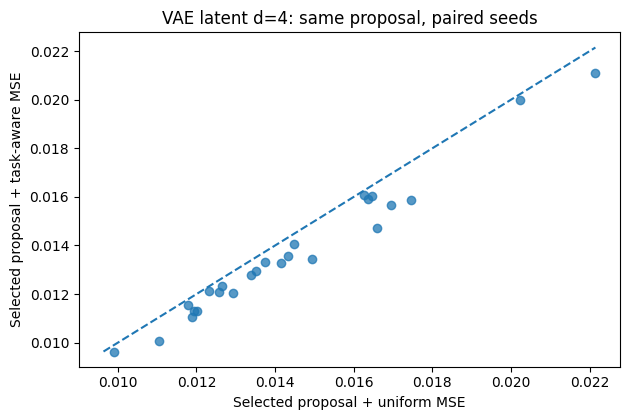

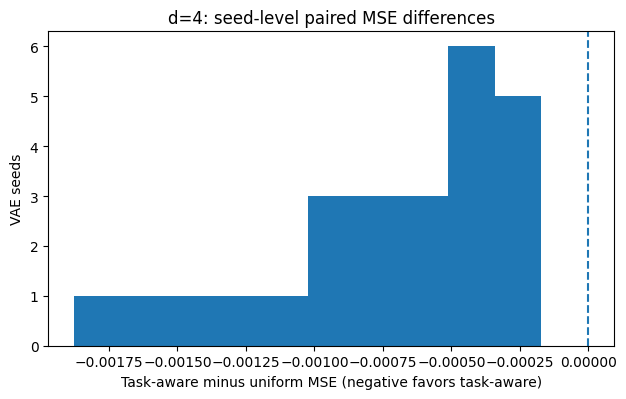

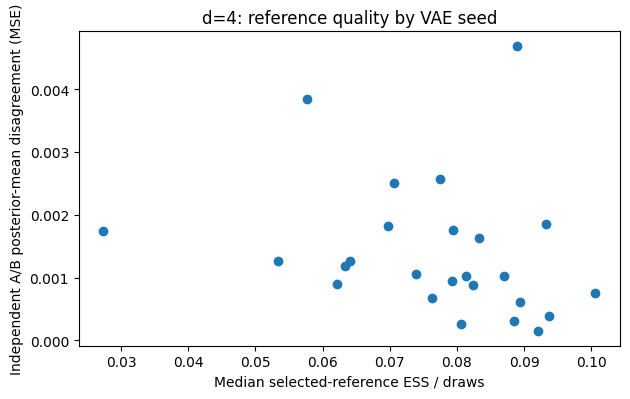

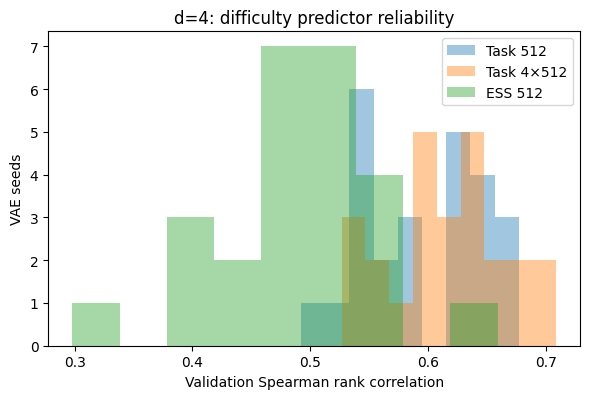

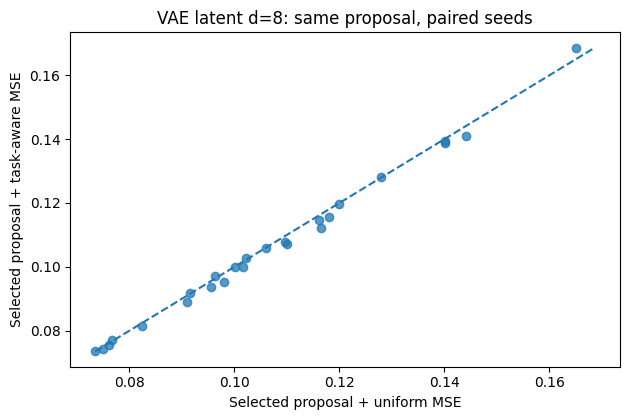

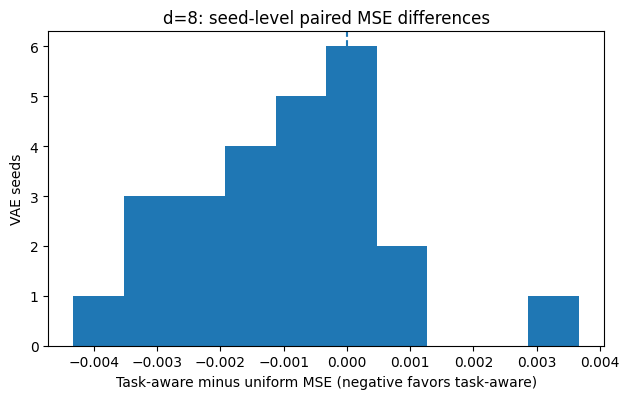

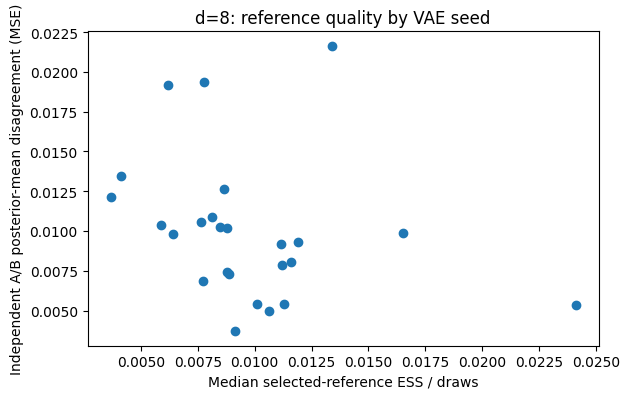

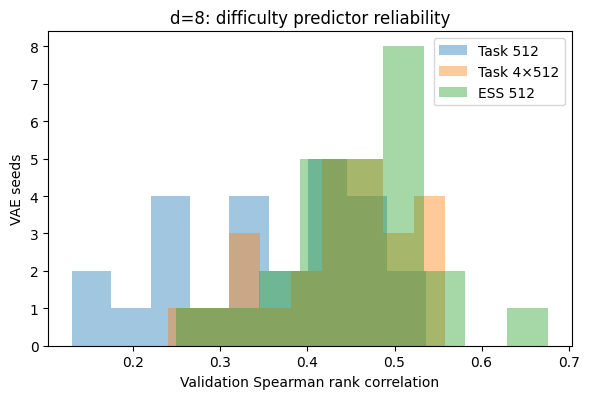

In [16]:
for dim in FC.dims:
    sd=SEED[SEED.dim==dim]
    p=sd.pivot(index='seed',columns='method',values='mse')
    fig,ax=plt.subplots(figsize=(6.4,4.3))
    a=p['SelectedTask512']; b=p['SelectedUniform'];
    lo=min(a.min(),b.min()); hi=max(a.max(),b.max())
    ax.scatter(b,a,alpha=.75);ax.plot([lo,hi],[lo,hi],'--')
    ax.set(xlabel='Selected proposal + uniform MSE',
           ylabel='Selected proposal + task-aware MSE',
           title=f'VAE latent d={dim}: same proposal, paired seeds')
    fig.tight_layout();fig.savefig(FUOUT/f'd{dim}_paired_primary.png',dpi=180)
    plt.show();plt.close(fig)

    fig,ax=plt.subplots(figsize=(6.4,4.1))
    diffs=(a-b).to_numpy();ax.hist(diffs,bins=min(10,max(3,len(diffs)//2)))
    ax.axvline(0,ls='--')
    ax.set(xlabel='Task-aware minus uniform MSE (negative favors task-aware)',
           ylabel='VAE seeds',title=f'd={dim}: seed-level paired MSE differences')
    fig.tight_layout();fig.savefig(FUOUT/f'd{dim}_paired_differences.png',dpi=180)
    plt.show();plt.close(fig)

    rv=REF[(REF.dim==dim) & ~REF.proposal_type.str.contains('matched_subset|encoder')]
    fig,ax=plt.subplots(figsize=(6.4,4.1))
    ax.scatter(rv.ref_ess_frac_median,rv.ref_pair_mse)
    ax.set(xlabel='Median selected-reference ESS / draws',
           ylabel='Independent A/B posterior-mean disagreement (MSE)',
           title=f'd={dim}: reference quality by VAE seed')
    fig.tight_layout();fig.savefig(FUOUT/f'd{dim}_reference_quality.png',dpi=180)
    plt.show();plt.close(fig)

    pv=PRED[PRED.dim==dim]
    fig,ax=plt.subplots(figsize=(6.0,4.1))
    for key,title in [('rank_rho_Task512','Task 512'),
                      ('rank_rho_Task4x512','Task 4×512'),
                      ('rank_rho_ESS512','ESS 512')]:
        ax.hist(pv[key].dropna(),alpha=.42,bins=9,label=title)
    ax.set(xlabel='Validation Spearman rank correlation',ylabel='VAE seeds',
           title=f'd={dim}: difficulty predictor reliability')
    ax.legend();fig.tight_layout();fig.savefig(FUOUT/f'd{dim}_difficulty_predictor.png',dpi=180)
    plt.show();plt.close(fig)

## 17 · Evidence audit and defensible SOP wording

Do **not** conclude that the theory is disproven if the selected reference is still unstable or the teacher ranks poorly. We report separate outcomes for proposal quality, sample allocation and predictor accuracy. Reference A/B agreement is a useful necessary check but not an accuracy guarantee. We never substitute the 4D/8D synthetic-Gaussian-mixture results for new VAE results.

In [17]:
statements=[]
for dim in FC.dims:
    main=CMP[(CMP.dim==dim)&(CMP.method=='SelectedTask512')&
             (CMP.baseline=='SelectedUniform')&(CMP.metric=='mse')].iloc[0]
    old=CMP[(CMP.dim==dim)&(CMP.method=='EncoderTask512')&
             (CMP.baseline=='EncoderUniform')&(CMP.metric=='mse')].iloc[0]
    diag=REF[(REF.dim==dim)&(~REF.proposal_type.str.contains('matched_subset|encoder'))]
    rpair=float(diag.ref_pair_mse.mean())
    essmedian=float(diag.ref_ess_frac_median.median())
    effect=abs(float(main.mean_paired_difference))
    support=(main.paired_95ci_high<0 and main.paired_signflip_p<.05)
    quality_warning=(rpair>max(effect,.00000001) or essmedian<.01)
    if support and not quality_warning:
        claim='The seed-level paired comparison favored task-aware allocation, subject to the approximate reference.'
    elif support:
        claim='The paired test favored task-aware allocation, but reference diagnostics limit what can be concluded.'
    else:
        claim='The paired test did not establish a reliable advantage for task-aware allocation.'
    txt=(f'For latent dimension {dim}, on {int(main.n_seeds)} separately trained VAEs and '
         f'{len(x_follow)} previously unused held-out digits, the validation-selected proposal gave '
         f'{main.relative_MSE_reduction_pct:.3f}% lower observed task-aware posterior-mean MSE '
         f'vs uniform allocation at a matched 48-draw online budget '
         f'(seed-level 95% CI for MSE difference '
         f'[{main.paired_95ci_low:.6g}, {main.paired_95ci_high:.6g}]; '
         f'paired signflip p={main.paired_signflip_p:.4g}). '
         f'{claim} Median reference ESS fraction was {essmedian:.3%}; '
         f'independent reference A/B MSE was {rpair:.6g}. '
         f'These findings are exploratory and depend on the proposal and approximate references.')
    statements.append(txt)

note='\n\n'.join(statements)
print(note)
(FUOUT/'SOP_evidence_audit.txt').write_text(note+'\n')
if FOLLOWUP_MODE=='smoke':
    print('\nSMOKE TEST: do not use these numbers as scientific results.')
print('Output folder:',FUOUT)

For latent dimension 4, on 25 separately trained VAEs and 104 previously unused held-out digits, the validation-selected proposal gave 4.934% lower observed task-aware posterior-mean MSE vs uniform allocation at a matched 48-draw online budget (seed-level 95% CI for MSE difference [-0.000899926, -0.000520913]; paired signflip p=3.333e-05). The paired test favored task-aware allocation, but reference diagnostics limit what can be concluded. Median reference ESS fraction was 7.943%; independent reference A/B MSE was 0.0014037. These findings are exploratory and depend on the proposal and approximate references.

For latent dimension 8, on 25 separately trained VAEs and 104 previously unused held-out digits, the validation-selected proposal gave 0.852% lower observed task-aware posterior-mean MSE vs uniform allocation at a matched 48-draw online budget (seed-level 95% CI for MSE difference [-0.00158337, -0.00023882]; paired signflip p=0.01007). The paired test favored task-aware allocatio

## 18 · ZIP the artifacts

Export contains all fitted models, regressor files, per-seed evidence, independent references, figures and the frozen configuration. In Colab, keep Drive persistence turned on if you will need to resume after a disconnect. **Do not share intermediate or smoke-test numbers as final results.**

In [18]:
import shutil
zip_path=shutil.make_archive(str(FUOUT),'zip',root_dir=str(FUOUT))
print('ZIP:',zip_path)
try:
    from google.colab import files
    print('If you want to download it locally: files.download(zip_path)')
except ImportError:pass

ZIP: /content/drive/MyDrive/TaskAware_VAE_Confirmation/followup_full_3dde513c60c2.zip
If you want to download it locally: files.download(zip_path)


### Interpretation checklist (read before SOP updates)

1. **Main conclusion** — Did `SelectedTask512` outperform `SelectedUniform` on **paired seed-level** MSE, including the 95% CI and sign-flip p-value? Neither a tiny negative difference nor improvement on one representative seed is enough.
2. **Reference quality** — Is A/B posterior-mean disagreement substantially below the online MSE scale? Are ESS fractions and early-to-final estimates reasonably stable? If not, write that posterior references remain unreliable; do not treat their MSE as exact posterior error.
3. **Proposal effect** — Did changing the proposal improve both ESS and reference agreement on an identical diagnostic image subset? A higher ESS alone can miss important modes.
4. **Predictor quality** — Did higher-budget validation rank agreement improve after 4 independent 512-draw teachers? At what **offline computational cost**?
5. **Matched budgets** — Within each proposal, all online allocators use the same total number of samples and identical random-number banks.
6. **Scope** — The findings are for the fixed-variance VAE likelihood, 8×8 digits and a fixed fresh test subset; they are not a general validation of task-aware importance sampling for all VAEs.
7. **Research integrity** — Because this follow-up was motivated by earlier observed results, treat its inferential claims as exploratory and plan genuine independent replication before claiming broad generalization.